# Deep Learning II: Representaciones, Modelos Secuenciales (RNN/LSTM) y Atención
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 90–100 minutos

Referencias: *Sequence Modeling* | [Keras RNN Guide](https://www.tensorflow.org/guide/keras/rnn) | Olah, *Understanding LSTM Networks*

---

### La historia de esta clase

Todo flujo de *machine learning* comparte una misma estructura:

> **Codificar** la entrada → construir una **representación** → **decodificar** la representación en una salida.

Recorreremos esa estructura desde el caso más simple hasta los modelos de lenguaje modernos:

1. **Representaciones** — ingeniería de características, *embeddings*, encoder–decoder y características aprendidas. Cuatro nombres, una sola idea.
2. **Datos secuenciales** — por qué las series de tiempo necesitan memoria; la idea de la RNN.
3. **LSTM** — memoria con compuertas para secuencias largas.
4. **Práctica** — RNN vs. LSTM vs. un modelo hidrológico con **caudales reales del río Ramis (estación Puente Ramis, CAMELS-PE)**, y un experimento de memoria.
5. **Atención** — dejar que el modelo decida en qué fijarse.
6. **Transformers** — atención apilada (la base de los LLM).
7. **Elegir la arquitectura según la estructura de los datos.**

### Objetivos de aprendizaje

Al finalizar, deberías poder:

- Describir la estructura **codificar → representar → decodificar** común a todo flujo de ML.
- Explicar la **ingeniería de características** y en qué se diferencia de las **representaciones aprendidas**.
- Explicar qué es un **embedding** y por qué embeddings, características diseñadas, encoders y decoders son la misma idea.
- Explicar por qué los datos secuenciales son difíciles para redes feedforward y qué aporta una **RNN**.
- Describir el **estado oculto**, el **estado de celda** y las tres **compuertas** de una LSTM.
- Entrenar y evaluar RNN y LSTM con caudales reales (NSE, KGE), comparándolas con un **modelo hidrológico** y con la **persistencia**.
- Dar la intuición de la **auto-atención** con la imagen Query/Key/Value.
- Asociar problemas ambientales peruanos con la arquitectura adecuada.

In [1]:
# Instalar TensorFlow si el entorno no lo trae (p. ej. algunos runtimes de Google Colab)
# La primera vez tarda ~1–2 minutos; después solo se importa.
import importlib.util, subprocess, sys

if importlib.util.find_spec('tensorflow') is None:
    print('Instalando TensorFlow...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'])

import tensorflow as tf
print(f'TensorFlow {tf.__version__} listo')

TensorFlow 2.21.0 listo


In [2]:
# Paquetes principales usados en todo el notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# 1. Representaciones: cómo ve el mundo un modelo

Un modelo de ML no entiende directamente expresiones como

- "inicio de la temporada de lluvias",
- "un friaje en la selva",
- "una sequía en el altiplano",
- "un paisaje de bosque amazónico",
- "una oración".

Solo ve **números**. Por eso la primera gran pregunta de todo flujo de ML es:

> **¿Cómo convertimos el mundo real en números que un modelo pueda usar?**

### 1.0 Un marco unificador: codificar → representar → decodificar

| Etapa | Qué ocurre | Quién lo hace |
|---|---|---|
| **Encoder** (codificador) | Convierte la entrada cruda en una representación útil | Ingeniería de características (manual), embeddings (aprendidos para datos discretos) o capas de red neuronal (aprendidas de extremo a extremo) |
| **Representación** | Un vector (o conjunto de vectores) que captura lo importante | Características diseñadas, vectores de embedding, estados ocultos, salidas de atención |
| **Decoder** (decodificador) | Transforma la representación en una predicción | Capa lineal, capa recurrente u otra red neuronal |

Este marco aparece en toda la clase:

- **ML clásico** (Labs 7–8): tú *diseñas* las características (codificas) y luego ajustas un modelo (decodificas).
- **Deep learning** (Labs 9_1–9_2): las capas *aprenden* conjuntamente el encoder y el decoder.
- **Embeddings**: un pequeño encoder aprendido para categorías (palabras, especies, estaciones).
- **LSTM**: la red recurrente codifica una secuencia paso a paso; una capa final decodifica.
- **Seq2seq / U-Net / Transformers**: encoder y decoder son módulos explícitos.

## 1.1 Ingeniería de características — un encoder manual para datos continuos

Una **característica** es una variable de entrada del modelo. Algunas se miden directamente (temperatura, precipitación, humedad del suelo, NDVI...). Otras se **diseñan** a partir de los datos crudos usando conocimiento del dominio:

- día del año → términos estacionales seno/coseno,
- NDVI del día anterior (un *rezago* o *lag*),
- precipitación acumulada de 7 días,
- un índice de sequía (SPI),
- interacciones como temperatura × humedad del suelo.

La ingeniería de características es un **encoder manual**: el humano decide qué transformación hace que los patrones sean más fáciles de aprender.

Ejemplo: una parcela de pastos en el **valle del Mantaro** (Junín), donde la temporada de lluvias va de diciembre a marzo.

In [3]:
# Tabla ambiental sintética, solo para demostrar características diseñadas
n_dias = 365
dia = np.arange(1, n_dias + 1)

# Hemisferio sur andino: lluvias dic–mar, máximo de verdor ~marzo-abril
temperatura = 12 + 3 * np.cos(2 * np.pi * (dia - 30) / 365) + np.random.normal(0, 1.2, n_dias)
precip = np.random.gamma(shape=1.2, scale=1.0, size=n_dias) * (1 + 3 * np.clip(np.cos(2 * np.pi * (dia - 30) / 365), 0, None))
humedad_suelo = 0.25 + 0.08 * np.cos(2 * np.pi * (dia - 60) / 365) + 0.01 * np.random.randn(n_dias)
ndvi = np.clip(0.40 + 0.20 * np.cos(2 * np.pi * (dia - 90) / 365)
               + 0.15 * humedad_suelo + np.random.normal(0, 0.03, n_dias), 0.05, 0.9)

df = pd.DataFrame({'dia_del_anio': dia, 'temperatura_C': temperatura, 'precip_mm': precip,
                   'humedad_suelo': humedad_suelo, 'NDVI': ndvi})

# Características diseñadas
df['estacion_sin'] = np.sin(2 * np.pi * df['dia_del_anio'] / 365)
df['estacion_cos'] = np.cos(2 * np.pi * df['dia_del_anio'] / 365)
df['NDVI_rezago_1d'] = df['NDVI'].shift(1)
df['precip_suma_7d'] = df['precip_mm'].rolling(7).sum()
df['temp_x_humedad'] = df['temperatura_C'] * df['humedad_suelo']

df.head(10).round(3)

,dia_del_anio,temperatura_C,precip_mm,humedad_suelo,NDVI,estacion_sin,estacion_cos,NDVI_rezago_1d,precip_suma_7d,temp_x_humedad
0,1,15.230,1.978,0.303,0.498,0.017,1.000,NaN,NaN,4.614
1,2,14.492,3.414,0.293,0.445,0.034,0.999,0.498,NaN,4.245
2,3,15.459,7.888,0.293,0.451,0.052,0.999,0.445,NaN,4.526
3,4,16.532,5.137,0.304,0.504,0.069,0.998,0.451,NaN,5.033
4,5,14.445,3.422,0.303,0.484,0.086,0.996,0.504,NaN,4.381
5,6,14.467,1.962,0.282,0.481,0.103,0.995,0.484,NaN,4.081
6,7,16.663,15.099,0.314,0.540,0.120,0.993,0.481,38.899,5.227
7,8,15.708,2.907,0.314,0.459,0.137,0.991,0.540,39.828,4.930
8,9,14.243,8.108,0.295,0.507,0.154,0.988,0.459,44.523,4.199
9,10,15.475,2.784,0.306,0.486,0.171,0.985,0.507,39.418,4.737


| Característica diseñada | Por qué ayuda |
|---|---|
| `estacion_sin`, `estacion_cos` | Pone el año en un círculo: el 31 de diciembre y el 1 de enero quedan juntos |
| `NDVI_rezago_1d` | Da memoria de corto plazo |
| `precip_suma_7d` | Captura la humedad acumulada reciente |
| `temp_x_humedad` | Permite que el efecto de la temperatura dependa del agua disponible |

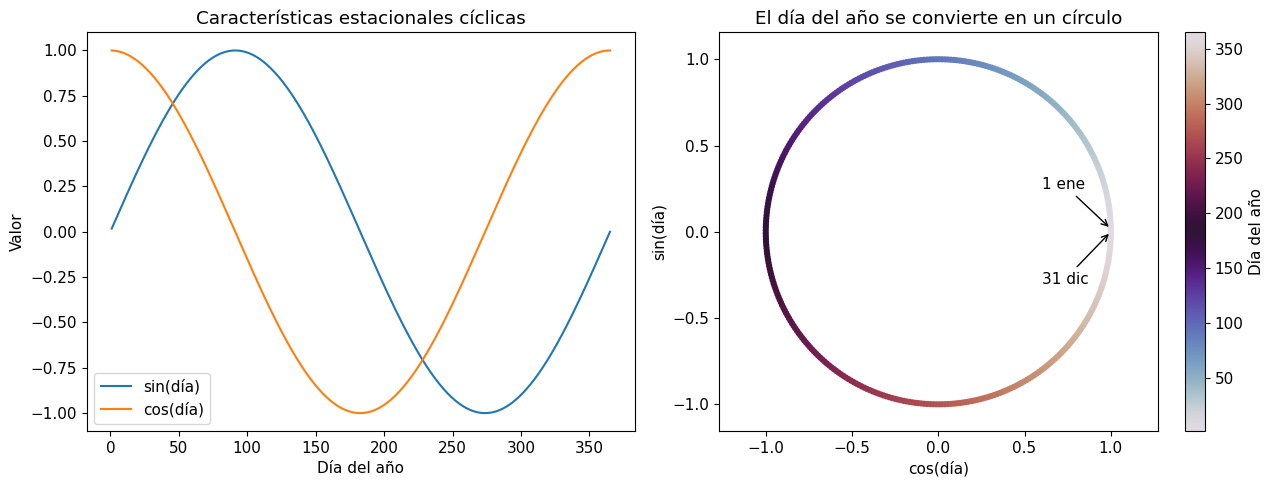

In [4]:
# ¿Por qué características cíclicas? El día 365 y el día 1 son vecinos en el ciclo real,
# pero como enteros parecen estar a 364 días de distancia. Seno/coseno los pone en un círculo.
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].plot(df['dia_del_anio'], df['estacion_sin'], label='sin(día)')
ejes[0].plot(df['dia_del_anio'], df['estacion_cos'], label='cos(día)')
ejes[0].set_title('Características estacionales cíclicas')
ejes[0].set_xlabel('Día del año'); ejes[0].set_ylabel('Valor'); ejes[0].legend()

sc = ejes[1].scatter(df['estacion_cos'], df['estacion_sin'], c=df['dia_del_anio'], cmap='twilight', s=12)
ejes[1].annotate('1 ene', (df['estacion_cos'][0], df['estacion_sin'][0]), xytext=(0.6, 0.25),
                 arrowprops=dict(arrowstyle='->'))
ejes[1].annotate('31 dic', (df['estacion_cos'][364], df['estacion_sin'][364]), xytext=(0.6, -0.3),
                 arrowprops=dict(arrowstyle='->'))
ejes[1].set_title('El día del año se convierte en un círculo')
ejes[1].set_xlabel('cos(día)'); ejes[1].set_ylabel('sin(día)'); ejes[1].axis('equal')
plt.colorbar(sc, ax=ejes[1], label='Día del año')
plt.tight_layout()
plt.show()

### Conexión con el marco

La ingeniería de características **es un encoder construido a mano**: tú, como científico, miras los datos crudos y produces una representación numérica más fácil de usar para el modelo. Las siguientes secciones muestran otros dos tipos de encoder —embeddings y capas neuronales— que hacen el mismo trabajo de otra forma.

## 1.2 Embeddings — un encoder aprendido para datos discretos

Muchas entradas importantes son **categorías discretas**: palabras, tipos de cobertura, especies, **códigos de estación SENAMHI**, tipos de cultivo...

Un modelo no puede usar directamente la palabra `"bosque"`. La opción más simple es el **one-hot encoding**:

| Categoría | Vector one-hot |
|---|---|
| bosque amazónico | [1, 0, 0, 0] |
| puna (pajonal) | [0, 1, 0, 0] |
| cultivo | [0, 0, 1, 0] |
| urbano | [0, 0, 0, 1] |

Los vectores one-hot son grandes (una dimensión por categoría) y **no expresan similitud**: todas las categorías están igual de lejos entre sí.

Un **embedding** reemplaza el one-hot por un vector denso corto cuyas coordenadas se **aprenden** durante el entrenamiento:

| Categoría | Embedding aprendido |
|---|---|
| bosque amazónico | [0.80, 0.25] |
| puna (pajonal) | [0.55, 0.45] |
| cultivo | [0.25, 0.70] |
| urbano | [-0.45, 0.85] |

El entrenamiento ubica **cerca** a las categorías que se *comportan* parecido para la tarea. Si la tarea premia agrupar bosque y puna (ambas vegetación natural), sus vectores se acercan.

Categoría:          puna
ID entero:          1
Vector one-hot:     [0. 1. 0. 0.]
Vector embedding:   [0.55 0.45]


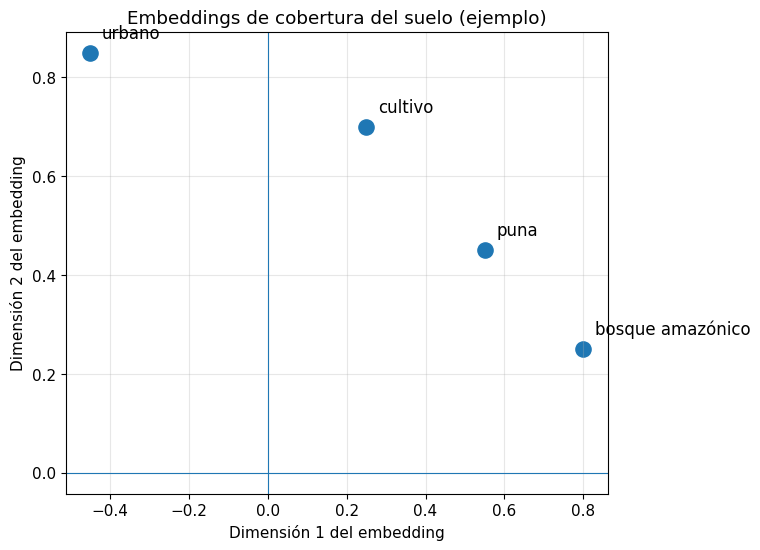

In [5]:
# One-hot vs. búsqueda en una tabla de embeddings
categorias = ['bosque amazónico', 'puna', 'cultivo', 'urbano']
cat_a_id = {c: i for i, c in enumerate(categorias)}

one_hot = np.eye(len(categorias))

# Matriz de embedding diseñada a mano, solo para ilustrar.
# En deep learning real estos números se APRENDEN.
matriz_embedding = np.array([
    [0.80, 0.25],   # bosque amazónico
    [0.55, 0.45],   # puna
    [0.25, 0.70],   # cultivo
    [-0.45, 0.85],  # urbano
])

ejemplo = 'puna'
idx = cat_a_id[ejemplo]
print(f"Categoría:          {ejemplo}")
print(f"ID entero:          {idx}")
print(f"Vector one-hot:     {one_hot[idx]}")
print(f"Vector embedding:   {matriz_embedding[idx]}")

plt.figure(figsize=(7, 6))
plt.scatter(matriz_embedding[:, 0], matriz_embedding[:, 1], s=120)
for c, (x, y) in zip(categorias, matriz_embedding):
    plt.text(x + 0.03, y + 0.03, c, fontsize=12)
plt.axhline(0, linewidth=0.8); plt.axvline(0, linewidth=0.8)
plt.xlabel('Dimensión 1 del embedding'); plt.ylabel('Dimensión 2 del embedding')
plt.title('Embeddings de cobertura del suelo (ejemplo)')
plt.grid(alpha=0.3)
plt.show()

### Los embeddings también son encoders

Observa el patrón:

- Las características cíclicas codifican el **día del año** en dos números cuya geometría (un círculo) refleja la estacionalidad.
- Los embeddings codifican **categorías** en vectores cuya geometría (cercanía) refleja similitud de comportamiento.

Ambos son *encoders*. La única diferencia es **quién decide las coordenadas**: tú (ingeniería) o el modelo (aprendizaje).

En los modelos de lenguaje, el embedding es lo primero que le ocurre a cada *token*: `"Ciencia"`, `"de"`, `"Datos"` se buscan en una enorme tabla de embeddings antes de que corra cualquier capa del Transformer.

## 1.3 Representaciones aprendidas — cuando el encoder es una red neuronal

La ingeniería de características tiene límites:

| Tipo de datos | Por qué es difícil diseñar características a mano |
|---|---|
| Imágenes satelitales | ¿Qué textura, borde o patrón espacial definimos? (Lab 9_2) |
| Series de tiempo | ¿Qué rezagos, ventanas y anomalías incluimos? |
| Texto (boletines, informes) | ¿Cómo representamos significado y contexto? |
| Datos hiperespectrales | ¿Qué bandas, cocientes y formas espectrales importan? |

El deep learning traslada el trabajo del humano al modelo:

> **ML clásico:** datos crudos → características diseñadas por humanos → modelo → predicción
>
> **Deep learning:** datos crudos → capas de red neuronal → representación *aprendida* → predicción

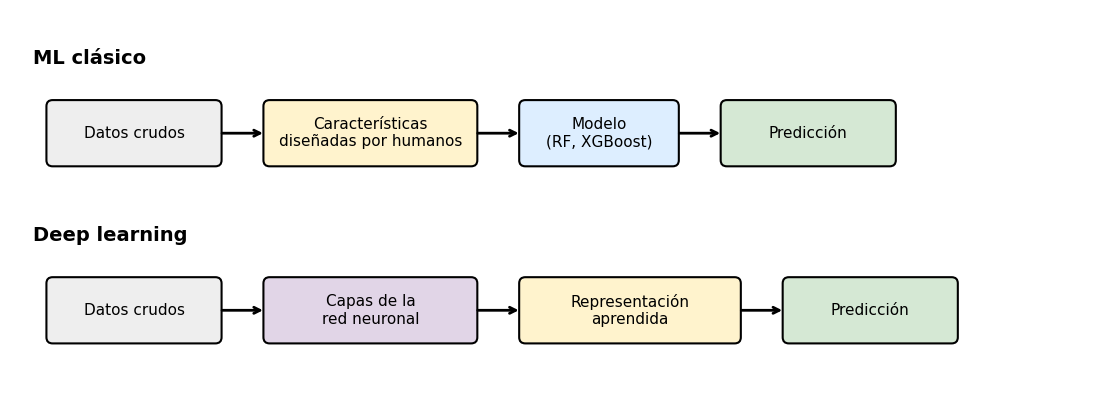

In [6]:
# Diagrama: ingeniería de características clásica vs. aprendizaje de representaciones
fig, ax = plt.subplots(figsize=(14, 5))
ax.axis('off'); ax.set_xlim(0, 14); ax.set_ylim(0, 5)

def caja(x, y, w, h, texto, color):
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03,rounding_size=0.08',
                                        linewidth=1.5, edgecolor='black', facecolor=color))
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center', fontsize=11)

def flecha(x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', lw=2))

ax.text(0.3, 4.3, 'ML clásico', fontsize=14, fontweight='bold')
caja(0.5, 3.0, 2.2, 0.8, 'Datos crudos', '#EEEEEE')
caja(3.3, 3.0, 2.7, 0.8, 'Características\ndiseñadas por humanos', '#FFF3CD')
caja(6.6, 3.0, 2.0, 0.8, 'Modelo\n(RF, XGBoost)', '#DDEEFF')
caja(9.2, 3.0, 2.2, 0.8, 'Predicción', '#D5E8D4')
flecha(2.7, 3.4, 3.3, 3.4); flecha(6.0, 3.4, 6.6, 3.4); flecha(8.6, 3.4, 9.2, 3.4)

ax.text(0.3, 2.0, 'Deep learning', fontsize=14, fontweight='bold')
caja(0.5, 0.7, 2.2, 0.8, 'Datos crudos', '#EEEEEE')
caja(3.3, 0.7, 2.7, 0.8, 'Capas de la\nred neuronal', '#E1D5E7')
caja(6.6, 0.7, 2.8, 0.8, 'Representación\naprendida', '#FFF3CD')
caja(10.0, 0.7, 2.2, 0.8, 'Predicción', '#D5E8D4')
flecha(2.7, 1.1, 3.3, 1.1); flecha(6.0, 1.1, 6.6, 1.1); flecha(9.4, 1.1, 10.0, 1.1)
plt.show()

### El modelo mental

Una red profunda es una **secuencia de transformaciones de representación**:

- **Modelo de imágenes:** píxeles → bordes → texturas → partes → objetos → clase (Lab 9_2)
- **Modelo de lenguaje:** tokens → significado de palabras → frases → contexto → siguiente token
- **Modelo de series ambientales:** observaciones diarias → patrones de tiempo de corto plazo → dinámica estacional → señales de perturbación (El Niño, friajes) → pronóstico

La arquitectura determina *qué tipo* de patrones puede aprender el modelo eficientemente.

## 1.4 Encoders y decoders en la práctica

Cuando entrada y salida son estructuradas (ambas secuencias o ambas imágenes), la red se divide explícitamente:

- **Encoder**: lee la entrada y construye una representación.
- **Decoder**: usa esa representación para generar la salida.

El encoder puede ser una LSTM, una CNN, un Transformer... lo importante es que produzca una representación útil. **Todo lo visto hasta ahora —características diseñadas, embeddings, capas neuronales— es un tipo de encoder.** El resto del notebook estudia encoders *específicos para secuencias*.

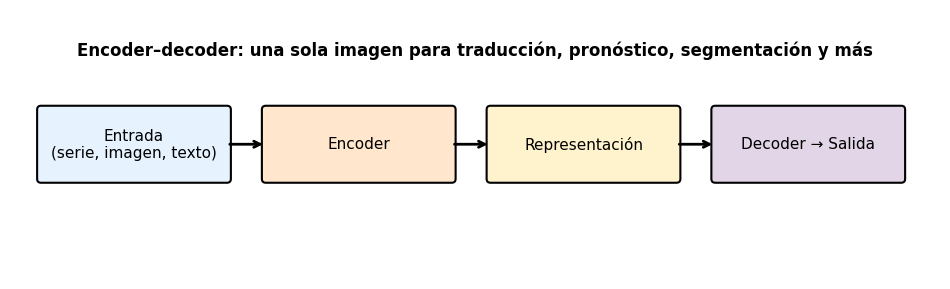

In [7]:
# Esquema compacto encoder–decoder
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axis('off'); ax.set_xlim(0, 12); ax.set_ylim(0, 3.5)

for x, texto, color in [(0.4, 'Entrada\n(serie, imagen, texto)', '#E6F3FF'),
                        (3.3, 'Encoder', '#FFE6CC'),
                        (6.2, 'Representación', '#FFF3CD'),
                        (9.1, 'Decoder → Salida', '#E1D5E7')]:
    ax.add_patch(patches.FancyBboxPatch((x, 1.3), 2.4, 0.9, boxstyle='round,pad=0.05',
                                        facecolor=color, edgecolor='black', lw=1.5))
    ax.text(x + 1.2, 1.75, texto, ha='center', va='center', fontsize=11)
for x1 in [2.8, 5.7, 8.6]:
    ax.annotate('', xy=(x1 + 0.5, 1.75), xytext=(x1, 1.75), arrowprops=dict(arrowstyle='->', lw=2))
ax.text(6, 2.9, 'Encoder–decoder: una sola imagen para traducción, pronóstico, segmentación y más',
        ha='center', fontsize=12, fontweight='bold')
plt.show()

# 2. Datos secuenciales: cuando el orden importa

Muchos datos ambientales del Perú son secuenciales:

- temperatura y precipitación diarias de estaciones SENAMHI,
- caudales horarios del río Rímac o del Ucayali,
- nivel del lago Titicaca,
- índices mensuales de sequía o del Niño Costero (ICEN),
- series de imágenes satelitales (NDVI cada 16 días),
- concentraciones horarias de PM2.5 en Lima.

En datos secuenciales **el orden de las observaciones contiene información**: la lluvia de hace 3 días genera escorrentía hoy, un suelo saturado responde distinto que uno seco.

Una red feedforward podría recibir como características fijas *"temperatura hoy, ayer, anteayer..."*, pero:
- el tamaño de entrada es **fijo**,
- debe aprender **desde cero** que la posición 1 va antes que la 2,
- no tiene forma natural de modelar dependencias largas.

Las **Redes Neuronales Recurrentes (RNN)** se diseñaron para incorporar ese orden.

## 2.1 RNN: construidas para recordar secuencias

Una RNN lee la secuencia **un paso a la vez**. En cada paso actualiza un **estado oculto**:

$$h_t = \tanh(W_x\, x_t + W_h\, h_{t-1} + b)$$

- $x_t$: entrada en el tiempo $t$ (p. ej. temperatura del día $t$)
- $h_t$: estado oculto en el tiempo $t$ ("memoria")
- $h_{t-1}$: estado oculto anterior
- **los mismos pesos** $W_x, W_h$ se reutilizan en cada paso

El estado oculto funciona como una **memoria en curso**. Analogía: un pronosticador del SENAMHI que lee el boletín de cada día ($x_t$), recuerda lo que leyó antes ($h_{t-1}$), actualiza su comprensión ($h_t$) y, tras 30 días, emite un pronóstico.

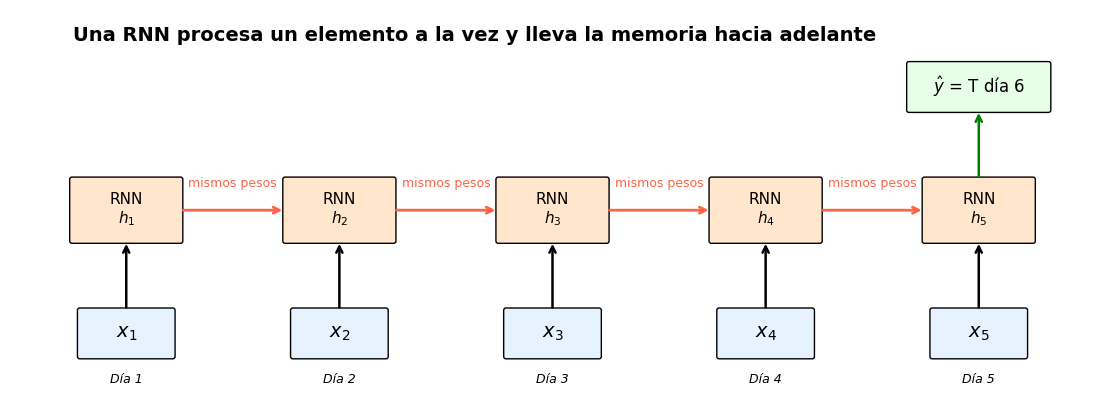

In [8]:
# Visualizar una RNN desplegada en el tiempo
fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14); ax.set_ylim(0, 5); ax.axis('off')

posiciones = np.linspace(1.5, 12.5, 5)
for i, x in enumerate(posiciones):
    t = i + 1
    ax.add_patch(patches.FancyBboxPatch((x-0.6, 0.5), 1.2, 0.6, boxstyle='round,pad=0.03',
                                        facecolor='#E6F3FF', edgecolor='black'))
    ax.text(x, 0.8, f'$x_{t}$', ha='center', va='center', fontsize=14)
    ax.text(x, 0.15, f'Día {t}', ha='center', fontsize=9, style='italic')
    ax.add_patch(patches.FancyBboxPatch((x-0.7, 2.0), 1.4, 0.8, boxstyle='round,pad=0.03',
                                        facecolor='#FFE6CC', edgecolor='black'))
    ax.text(x, 2.4, f'RNN\n$h_{t}$', ha='center', va='center', fontsize=11)
    ax.annotate('', xy=(x, 2.0), xytext=(x, 1.1), arrowprops=dict(arrowstyle='->', lw=1.8))
    if i < len(posiciones) - 1:
        ax.annotate('', xy=(posiciones[i+1]-0.7, 2.4), xytext=(x+0.7, 2.4),
                    arrowprops=dict(arrowstyle='->', lw=2, color='tomato'))
        ax.text((x + posiciones[i+1]) / 2, 2.7, 'mismos pesos', ha='center', fontsize=9, color='tomato')

x = posiciones[-1]
ax.add_patch(patches.FancyBboxPatch((x-0.9, 3.7), 1.8, 0.6, boxstyle='round,pad=0.03',
                                    facecolor='#E6FFE6', edgecolor='black'))
ax.text(x, 4.0, r'$\hat{y}$ = T día 6', ha='center', va='center', fontsize=12)
ax.annotate('', xy=(x, 3.7), xytext=(x, 2.8), arrowprops=dict(arrowstyle='->', lw=1.8, color='green'))
ax.text(6, 4.6, 'Una RNN procesa un elemento a la vez y lleva la memoria hacia adelante',
        ha='center', fontsize=14, fontweight='bold')
plt.show()

### Una RNN "a mano" con NumPy

Para desmitificarla, programemos el paso hacia adelante de una RNN de 3 neuronas que lee 15 días de precipitación. Los pesos aquí son aleatorios (no entrenados); lo importante es ver **cómo el estado oculto acumula la historia**.

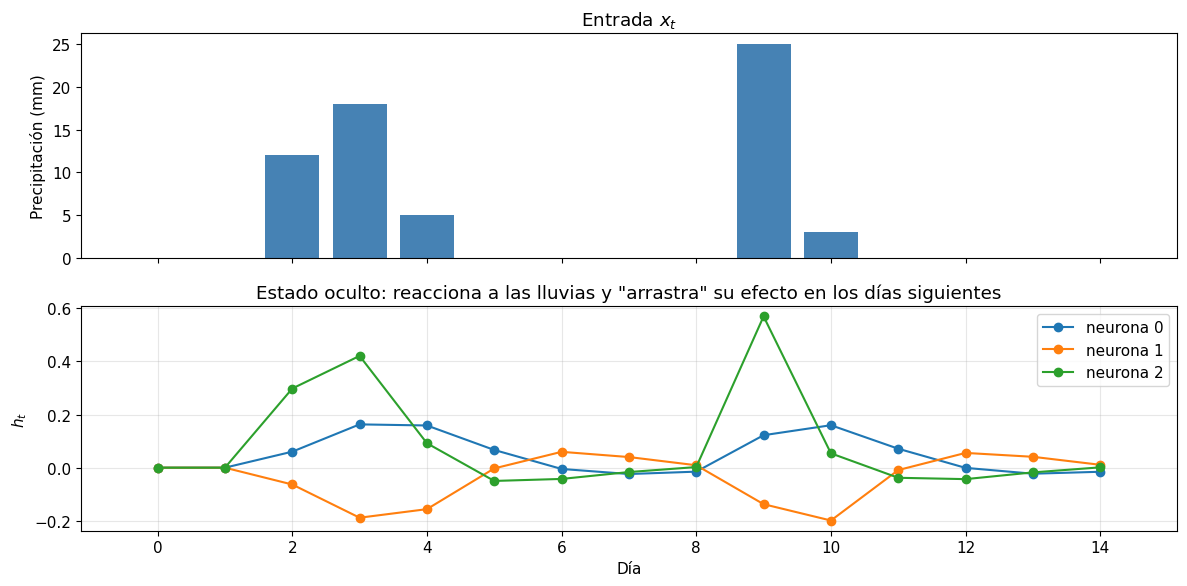

In [9]:
rng = np.random.default_rng(0)
precip_dias = np.array([0, 0, 12, 18, 5, 0, 0, 0, 0, 25, 3, 0, 0, 0, 0], dtype=float) / 25  # escalada

n_ocultas = 3
W_x = rng.normal(0, 1.0, (n_ocultas, 1))           # entrada → oculto
W_h = rng.normal(0, 0.5, (n_ocultas, n_ocultas))   # oculto → oculto (la recurrencia)
b = np.zeros(n_ocultas)

h = np.zeros(n_ocultas)
historial_h = []
for x_t in precip_dias:
    h = np.tanh(W_x @ [x_t] + W_h @ h + b)   # ¡la misma fórmula en cada paso!
    historial_h.append(h.copy())
historial_h = np.array(historial_h)

fig, ejes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ejes[0].bar(range(15), precip_dias * 25, color='steelblue')
ejes[0].set_ylabel('Precipitación (mm)'); ejes[0].set_title('Entrada $x_t$')
for k in range(n_ocultas):
    ejes[1].plot(historial_h[:, k], 'o-', label=f'neurona {k}')
ejes[1].set_ylabel('$h_t$'); ejes[1].set_xlabel('Día')
ejes[1].set_title('Estado oculto: reacciona a las lluvias y "arrastra" su efecto en los días siguientes')
ejes[1].legend(); ejes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.2 El problema del gradiente desvaneciente

Las RNN son elegantes, pero luchan con las **dependencias de largo plazo**.

Al entrenar, los gradientes deben fluir hacia atrás a través de muchos pasos de tiempo. Si se multiplican repetidamente por valores menores que 1, **se encogen hacia cero** (como un interés compuesto al revés). El modelo no logra aprender que algo ocurrido al inicio de la secuencia importa al final.

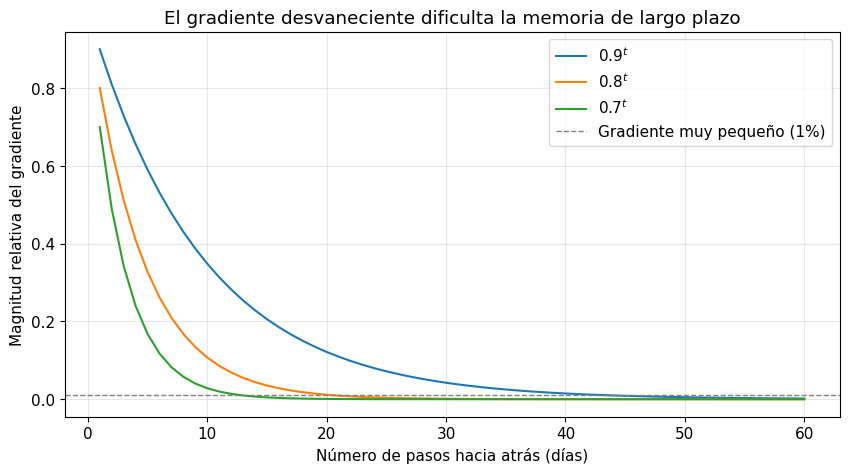

In [10]:
# Decaimiento del gradiente a través del tiempo
pasos = np.arange(1, 61)
plt.figure(figsize=(10, 5))
for factor in [0.9, 0.8, 0.7]:
    plt.plot(pasos, factor ** pasos, label=f'{factor}$^t$')
plt.axhline(0.01, linestyle='--', linewidth=1, color='gray', label='Gradiente muy pequeño (1%)')
plt.xlabel('Número de pasos hacia atrás (días)')
plt.ylabel('Magnitud relativa del gradiente')
plt.title('El gradiente desvaneciente dificulta la memoria de largo plazo')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Intuición en el contexto peruano

Imagina pronosticar el **caudal del río Rímac en agosto** (estiaje). Señales relevantes:

- las lluvias de **febrero–marzo** en la cuenca alta (recarga de acuíferos y lagunas),
- el retroceso de los glaciares de la Cordillera Central,
- un evento de **Niño Costero** meses atrás,
- la operación de represas aguas arriba.

Una RNN simple tiende a enfocarse en las observaciones **recientes**, porque la información antigua se vuelve difícil de aprender. Ese es el hueco que vinieron a llenar las LSTM.

# 3. LSTM: RNN con memoria controlada

Una **Long Short-Term Memory** (LSTM; Hochreiter & Schmidhuber, 1997) es una RNN diseñada para conservar información importante durante secuencias largas. Separa:

- un **estado oculto** $h_t$ — memoria de trabajo de corto plazo, usada para la salida,
- un **estado de celda** $C_t$ — memoria de largo plazo que viaja en el tiempo con mínima interferencia,
- tres **compuertas** — interruptores aprendidos que deciden qué olvidar, qué añadir y qué revelar.

Las compuertas no se programan a mano: **se aprenden de los datos**.

## 3.1 Las tres compuertas

En cada paso, la LSTM se hace tres preguntas:

| Compuerta | Pregunta | Ejemplo hidrológico |
|---|---|---|
| **Olvido** $f_t$ | ¿Qué información vieja borro del estado de celda? | "La lluvia de la semana pasada ya drenó; puedo olvidarla" |
| **Entrada** $i_t$ | ¿Qué información nueva añado? | "Hoy cayó una tormenta fuerte en la cuenca alta: lo anoto" |
| **Salida** $o_t$ | ¿Qué parte del estado de celda expongo ahora? | "Para el caudal de mañana, lo relevante es la humedad acumulada" |

**Analogía:** el estado de celda es un **cuaderno de campo** que llevas a lo largo del tiempo. La compuerta de olvido es el **borrador**, la de entrada es el **lápiz**, y la de salida decide **qué líneas lees en voz alta** en cada paso.

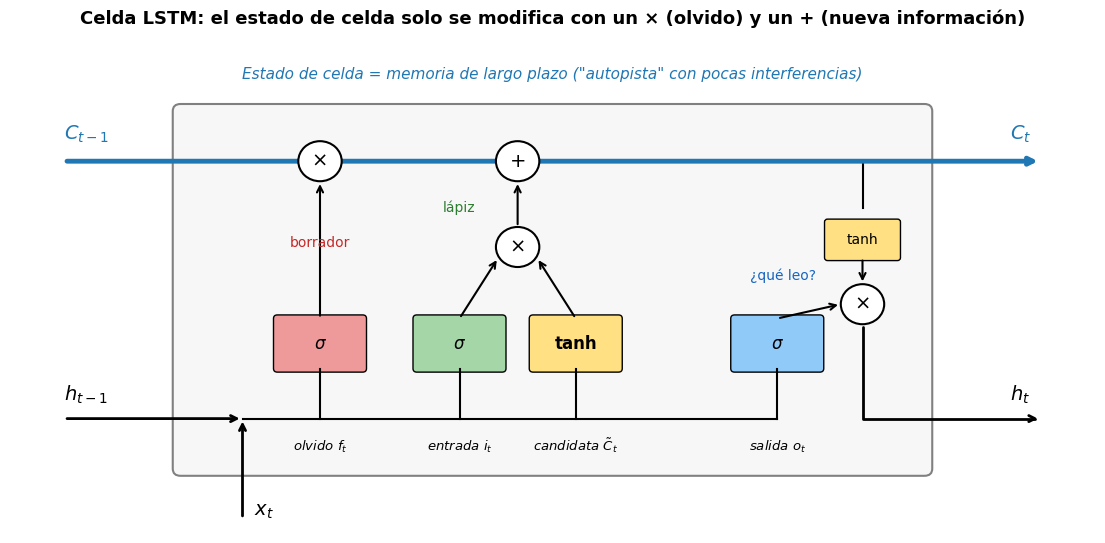

In [11]:
# Diagrama de una celda LSTM
fig, ax = plt.subplots(figsize=(14, 6.5))
ax.set_xlim(0, 14); ax.set_ylim(0, 7); ax.axis('off')

# Contorno de la celda
ax.add_patch(patches.FancyBboxPatch((2.2, 0.9), 9.6, 5.0, boxstyle='round,pad=0.1',
                                    facecolor='#F7F7F7', edgecolor='gray', lw=1.5))

# Autopista del estado de celda (arriba)
ax.annotate('', xy=(13.3, 5.2), xytext=(0.7, 5.2), arrowprops=dict(arrowstyle='->', lw=3.5, color='#1f77b4'))
ax.text(0.7, 5.5, '$C_{t-1}$', fontsize=14, color='#1f77b4')
ax.text(12.9, 5.5, '$C_t$', fontsize=14, color='#1f77b4')
ax.text(7, 6.35, 'Estado de celda = memoria de largo plazo ("autopista" con pocas interferencias)',
        ha='center', fontsize=11, color='#1f77b4', style='italic')

# Línea del estado oculto (abajo)
ax.annotate('', xy=(3.0, 1.6), xytext=(0.7, 1.6), arrowprops=dict(arrowstyle='->', lw=2))
ax.text(0.7, 1.85, '$h_{t-1}$', fontsize=14)
ax.annotate('', xy=(3.0, 1.6), xytext=(3.0, 0.2), arrowprops=dict(arrowstyle='->', lw=2))
ax.text(3.15, 0.25, '$x_t$', fontsize=14)
ax.plot([3.0, 9.9], [1.6, 1.6], 'k-', lw=1.5)

def compuerta(x, texto, color, etiqueta):
    ax.add_patch(patches.FancyBboxPatch((x-0.55, 2.3), 1.1, 0.7, boxstyle='round,pad=0.05',
                                        facecolor=color, edgecolor='black'))
    ax.text(x, 2.65, texto, ha='center', va='center', fontsize=12, fontweight='bold')
    ax.plot([x, x], [1.6, 2.3], 'k-', lw=1.5)
    ax.text(x, 1.15, etiqueta, ha='center', fontsize=9.5, style='italic')

def operador(x, y, simbolo):
    ax.add_patch(plt.Circle((x, y), 0.28, facecolor='white', edgecolor='black', lw=1.5, zorder=3))
    ax.text(x, y, simbolo, ha='center', va='center', fontsize=14, zorder=4)

compuerta(4.0, r'$\sigma$', '#EF9A9A', 'olvido $f_t$')
compuerta(5.8, r'$\sigma$', '#A5D6A7', 'entrada $i_t$')
compuerta(7.3, 'tanh', '#FFE082', r'candidata $\tilde{C}_t$')
compuerta(9.9, r'$\sigma$', '#90CAF9', 'salida $o_t$')

operador(4.0, 5.2, '×')                       # f_t * C_{t-1}
ax.annotate('', xy=(4.0, 4.92), xytext=(4.0, 3.0), arrowprops=dict(arrowstyle='->', lw=1.5))
operador(6.55, 4.0, '×')                      # i_t * C~_t
ax.annotate('', xy=(6.3, 3.85), xytext=(5.8, 3.0), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(6.8, 3.85), xytext=(7.3, 3.0), arrowprops=dict(arrowstyle='->', lw=1.5))
operador(6.55, 5.2, '+')
ax.annotate('', xy=(6.55, 4.92), xytext=(6.55, 4.28), arrowprops=dict(arrowstyle='->', lw=1.5))

# Salida: h_t = o_t * tanh(C_t)
ax.plot([11.0, 11.0], [5.2, 4.55], 'k-', lw=1.5)
ax.add_patch(patches.FancyBboxPatch((10.55, 3.85), 0.9, 0.5, boxstyle='round,pad=0.04',
                                    facecolor='#FFE082', edgecolor='black'))
ax.text(11.0, 4.1, 'tanh', ha='center', va='center', fontsize=10)
operador(11.0, 3.2, '×')
ax.annotate('', xy=(11.0, 3.48), xytext=(11.0, 3.85), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(10.72, 3.2), xytext=(9.9, 3.0), arrowprops=dict(arrowstyle='->', lw=1.5))
ax.annotate('', xy=(13.3, 1.6), xytext=(11.0, 2.92),
            arrowprops=dict(arrowstyle='->', lw=2, connectionstyle='angle,angleA=-90,angleB=180'))
ax.text(12.9, 1.85, '$h_t$', fontsize=14)
ax.annotate('', xy=(11.0, 6.9), xytext=(11.0, 3.48), arrowprops=dict(arrowstyle='-', lw=0))

ax.text(4.0, 4.0, 'borrador', ha='center', fontsize=10, color='#C62828')
ax.text(6.0, 4.5, 'lápiz', ha='right', fontsize=10, color='#2E7D32')
ax.text(10.4, 3.55, '¿qué leo?', ha='right', fontsize=10, color='#1565C0')
ax.set_title('Celda LSTM: el estado de celda solo se modifica con un × (olvido) y un + (nueva información)',
             fontsize=13, fontweight='bold')
plt.show()

### Fórmulas de la LSTM

En el paso $t$, la LSTM recibe la entrada actual $x_t$, el estado oculto anterior $h_{t-1}$ y el estado de celda anterior $C_{t-1}$. Produce $h_t$ y $C_t$:

$$f_t = \sigma(W_f [h_{t-1}, x_t] + b_f) \qquad \text{(compuerta de olvido)}$$

$$i_t = \sigma(W_i [h_{t-1}, x_t] + b_i) \qquad \text{(compuerta de entrada)}$$

$$\tilde{C}_t = \tanh(W_C [h_{t-1}, x_t] + b_C) \qquad \text{(estado de celda candidato)}$$

$$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t \qquad \text{(actualización de la memoria)}$$

$$o_t = \sigma(W_o [h_{t-1}, x_t] + b_o) \qquad \text{(compuerta de salida)}$$

$$h_t = o_t \odot \tanh(C_t) \qquad \text{(estado oculto / salida)}$$

donde $\sigma$ es la sigmoide (salida entre 0 y 1: "cuánto dejo pasar"), $\tanh$ da valores entre −1 y 1, $\odot$ es el producto elemento a elemento, y $W$, $b$ son pesos y sesgos entrenables.

La ecuación más importante es la actualización del estado de celda:

$$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t \quad\Longleftrightarrow\quad \text{memoria nueva} = \text{memoria vieja que conservo} + \text{información nueva que guardo}$$

🔑 **Por qué resuelve el gradiente desvaneciente:** el estado de celda se actualiza con una **suma**, no pasando por una $\tanh$ con pesos en cada paso. Si $f_t \approx 1$, la información (y su gradiente) viaja muchos pasos casi intacta.

In [ ]:
# Efecto de la compuerta de olvido: ¿cuánto sobrevive un evento después de N días?
dias = np.arange(0, 61)
plt.figure(figsize=(10, 4.5))
for f in [0.5, 0.9, 0.97, 0.995]:
    plt.plot(dias, f ** dias, label=f'$f_t$ = {f}')
plt.xlabel('Días después de una tormenta')
plt.ylabel('Fracción de la memoria que persiste en $C_t$')
plt.title('La LSTM APRENDE el valor de la compuerta de olvido: memoria corta o larga según la tarea')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# 4. Práctica A: caudales del río Ramis en la estación Puente Ramis (CAMELS-PE, cuenca del Titicaca)

> **Adaptación de la tarea:** se usa la estación hidrométrica **Puente Ramis** (`PE_47251282`), en la cuenca del lago **Titicaca**, con datos descargados de **CAMELS-PE** (SENAMHI). Se conserva la metodología, la secuencia de actividades y las arquitecturas RNN/LSTM del profesor.

Para esta cuenca se descargaron series diarias 1981–2025 en archivos separados (uno por variable):

| Variable | Descripción | Archivo descargado |
|---|---|---|
| `prec` | Precipitación media de la cuenca (mm/d); en el archivo se llama `prec_pisco` | Precipitacion |
| `tmin`, `tmean`, `tmax` | Temperatura del aire (°C) | Temperatura |
| `srad` | Radiación solar (MJ/m²/d) | Radiacion_solar |
| `vprp` | Presión de vapor (hPa) | Presion_de_vapor |
| `flow_obs` | **Caudal observado** (mm/d) | Caudales |
| `flow_sim` | Caudal simulado por el modelo hidrológico **PISCO-ARNOVIC** (mm/d) | Caudales |
| `pet_hs` | Evapotranspiración potencial (descargada, **no se usa**: no está en la práctica original) | ETP |

**Estación Puente Ramis (`PE_47251282`):** cuenca del Titicaca (altiplano). En el hidrograma las crecidas ocurren en el verano austral (enero–marzo) y el resto del año hay caudales bajos.

### Dos tareas, como en la hidrología operativa

1. **A1 · Simulación lluvia–escorrentía:** el modelo recibe **solo meteorología** (los últimos 180 días) y estima el caudal de hoy. Es la misma tarea que resuelve un modelo hidrológico como PISCO-ARNOVIC, así que podemos compararlos directamente (Kratzert et al., 2018).
2. **A2 · Pronóstico:** además de la meteorología, el modelo recibe el **caudal observado** de los días previos (*asimilación de datos*) y pronostica el caudal a 1, 3 y 7 días.

### Métricas hidrológicas

- **NSE** (Nash–Sutcliffe): $1 - \frac{\sum (Q_{obs} - Q_{sim})^2}{\sum (Q_{obs} - \bar{Q}_{obs})^2}$. Vale 1 si es perfecto, y 0 si equivale a predecir siempre la media; puede ser negativo.
- **KGE** (Kling–Gupta): combina correlación, sesgo y variabilidad. Vale 1 si es perfecto; un KGE > −0.41 ya supera a la media.

In [3]:
import os
import pandas as pd

# Caudal y meteorología diaria de Puente Ramis (CAMELS-PE)
GAUGE = 'PE_47251282'

# ID real del archivo de Google Drive (extraído de la URL compartida)
ID_DRIVE = '1oGNQs18pbwx3huCtRFtI2SVo8oQdWo8T'
ARCHIVO = f'{GAUGE}.csv'

if not os.path.exists(ARCHIVO):
    try:
        import gdown
        # Descarga usando el ID de archivo directamente
        gdown.download(id=ID_DRIVE, output=ARCHIVO, quiet=False)
    except Exception:
        import urllib.request
        # Enlace directo de descarga como alternativa
        url = f'https://docs.google.com/uc?export=download&id={ID_DRIVE}'
        urllib.request.urlretrieve(url, ARCHIVO)

camels = pd.read_csv(ARCHIVO, parse_dates=['date'], index_col='date')

print(f"Estación: {GAUGE}")
print(f"Periodo: {camels.index.min().date()} a {camels.index.max().date()} ({len(camels)} días)")
print(f"Días con caudal observado: {camels['flow_obs'].notna().sum()} "
      f"({camels['flow_obs'].notna().mean():.0%})")

camels.describe().T.round(2)

Downloading...
From: https://drive.google.com/uc?id=1oGNQs18pbwx3huCtRFtI2SVo8oQdWo8T
To: /content/PE_47251282.csv
100%|██████████| 1.33M/1.33M [00:00<00:00, 128MB/s]

Estación: PE_47251282
Periodo: 1981-01-01 a 2025-12-31 (16436 días)
Días con caudal observado: 12473 (76%)


,count,mean,std,min,25%,50%,75%,max
flow_obs,12473.0,0.41,0.55,0.01,0.07,0.13,0.56,3.18
flow_sim,16436.0,0.44,0.58,0.01,0.07,0.15,0.59,3.18
flow_obs_raw,12492.0,0.41,0.55,0.01,0.07,0.13,0.56,3.18
flow_obs_flag,16436.0,2.93,3.41,1.00,1.00,1.00,1.00,9.00
pet_hs,16436.0,3.23,0.54,1.74,2.80,3.19,3.62,4.94
prec,16436.0,1.91,2.63,0.00,0.06,0.68,2.90,19.55
vprp,16436.0,5.90,1.56,0.86,4.61,6.21,7.26,9.10
srad,16436.0,22.56,3.35,7.96,20.37,22.32,24.68,33.64
tmin,16436.0,-1.56,4.00,-13.12,-4.97,-0.62,1.97,5.06
tmean,16436.0,6.76,2.09,0.00,5.12,7.30,8.42,11.23


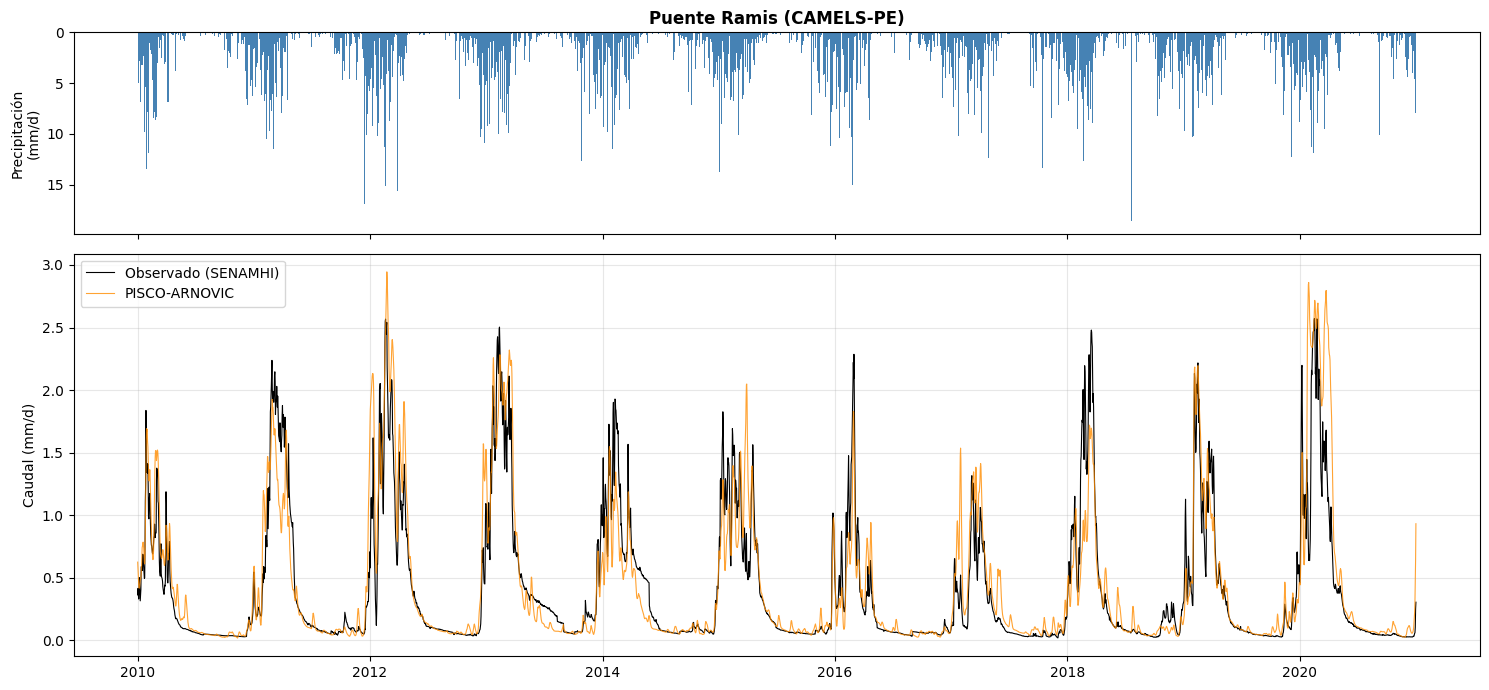

Desempeño de PISCO-ARNOVIC (solo días con caudal observado):
  1998–2010:  NSE =  0.792   KGE = 0.891
  2011–2015:  NSE =  0.798   KGE = 0.892
  2016–2020:  NSE =  0.697   KGE = 0.799


In [8]:
import numpy as np
import matplotlib.pyplot as plt

def nse(obs, sim):
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)

def kge(obs, sim):
    r = np.corrcoef(obs, sim)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (sim.std() / obs.std() - 1) ** 2 + (sim.mean() / obs.mean() - 1) ** 2)

fig, ejes = plt.subplots(2, 1, figsize=(15, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
tramo = camels.loc['2010':'2020']
ejes[0].bar(tramo.index, tramo['prec'], width=1, color='steelblue')
ejes[0].invert_yaxis(); ejes[0].set_ylabel('Precipitación\n(mm/d)')
ejes[0].set_title('Puente Ramis (CAMELS-PE)', fontweight='bold')
ejes[1].plot(tramo.index, tramo['flow_obs'], 'k-', lw=0.8, label='Observado (SENAMHI)')
ejes[1].plot(tramo.index, tramo['flow_sim'], '-', color='darkorange', lw=0.8, alpha=0.8, label='PISCO-ARNOVIC')
ejes[1].set_ylabel('Caudal (mm/d)'); ejes[1].legend(); ejes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ¿Qué tan bien simula el modelo hidrológico en cada periodo?
print('Desempeño de PISCO-ARNOVIC (solo días con caudal observado):')
for ini, fin in [('1998', '2010'), ('2011', '2015'), ('2016', '2020')]:
    t = camels.loc[ini:fin].dropna(subset=['flow_obs'])
    print(f"  {ini}–{fin}:  NSE = {nse(t['flow_obs'], t['flow_sim']):6.3f}   KGE = {kge(t['flow_obs'], t['flow_sim']):.3f}")

### Preparación de los datos

- **Periodos** (división cronológica): entrenamiento **1998–2010**, validación **2011–2015** (para *early stopping*) y prueba **2016–2020**. Se conserva el corte de 2020 para mantener la metodología de la práctica.
- **Normalización** con media y desviación calculadas usando únicamente el periodo de entrenamiento.
- **Logaritmo del caudal:** se utiliza para reducir la asimetría entre crecidas y estiajes.
- **Huecos:** el caudal observado empieza el **01/09/1991**. Solo se consideran como objetivo los días con `flow_obs` observado. No se reemplaza el caudal observado faltante en el objetivo con `flow_sim`; este último solo se usa como entrada auxiliar en A2.
- **Variables de entrada de A1:** `prec`, `tmean`, `tmax`, `tmin`, `srad` y `vprp`. `pet_hs` se conserva en la tabla integrada, pero no se incorpora al modelo para mantener las seis entradas de la práctica.

In [9]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

VARS_MET = ['prec', 'tmean', 'tmax', 'tmin', 'srad', 'vprp']
df = camels.loc['1996-01-01':'2020-12-31'].copy()   # 2 años extra para llenar las primeras ventanas
entrena = df.index <= '2010-12-31'

X_met = df[VARS_MET].values.astype('float32')
X_met_n = (X_met - X_met[entrena].mean(0)) / X_met[entrena].std(0)

q_obs = df['flow_obs'].values
q_log = np.log(q_obs + 0.05)
q_media, q_desv = np.nanmean(q_log[entrena]), np.nanstd(q_log[entrena])
q_n = (q_log - q_media) / q_desv

def a_caudal(v):
    # De la escala normalizada-log de vuelta a mm/d
    return np.maximum(np.exp(np.asarray(v) * q_desv + q_media) - 0.05, 0)

def crear_ventanas(X, ventana, horizonte=0):
    # Ventanas que terminan en t; el objetivo es el caudal observado en t + horizonte
    t = np.arange(ventana - 1, len(X) - horizonte)
    t = t[~np.isnan(q_obs[t + horizonte]) & (df.index[t] >= '1998-01-01')]
    Xw = np.stack([X[i - ventana + 1:i + 1] for i in t])
    fechas = df.index[t + horizonte]
    periodos = {'entrena': fechas <= '2010-12-31',
                'valida': (fechas > '2010-12-31') & (fechas <= '2015-12-31'),
                'prueba': fechas >= '2016-01-01'}
    return Xw, t, fechas, periodos

def entrenar(capa, Xw, y, periodos, epocas=40):
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([keras.Input(shape=Xw.shape[1:]), capa,
                               layers.Dropout(0.2), layers.Dense(1)])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
    e, v = periodos['entrena'], periodos['valida']
    t0 = time.time()
    hist = modelo.fit(Xw[e], y[e], epochs=epocas, batch_size=128, validation_data=(Xw[v], y[v]),
                      callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
                      verbose=0)
    print(f"  {capa.__class__.__name__:<10s} {len(hist.history['loss']):2d} épocas, {time.time() - t0:5.1f} s")
    return modelo, hist

filas_tabla = []   # aquí se acumulan las métricas de prueba para la tabla comparativa final


## A1 · Simulación lluvia–escorrentía: RNN vs. LSTM vs. PISCO-ARNOVIC

Entrada: **180 días** de las 6 variables meteorológicas → tensor `(muestras, 180, 6)`. Salida: el caudal del último día. La respuesta de la cuenca a la lluvia dura semanas a meses (recarga de suelos, acuíferos y lagunas), así que necesitamos **memoria larga**.

In [10]:
VENTANA_SIM = 180
Xs, ts, fechas_s, per_s = crear_ventanas(X_met_n, VENTANA_SIM)
ys = q_n[ts].astype('float32')
print(f"Tensor de entrada: {Xs.shape}  → (muestras, días, variables)")
print({k: int(v.sum()) for k, v in per_s.items()})

print('Entrenando...')
rnn_sim, hist_rnn_sim = entrenar(layers.SimpleRNN(32), Xs, ys, per_s)
lstm_sim, hist_lstm_sim = entrenar(layers.LSTM(32), Xs, ys, per_s)

Tensor de entrada: (8380, 180, 6)  → (muestras, días, variables)
{'entrena': 4729, 'valida': 1824, 'prueba': 1827}
Entrenando...
  SimpleRNN  40 épocas,  63.0 s
  LSTM       13 épocas,  53.6 s


Modelo (prueba 2016–2020)       NSE    KGE   RMSE    MAE
--------------------------------------------------------
PISCO-ARNOVIC (hidrológico)   0.697  0.799  0.290  0.143
RNN simple                    0.804  0.668  0.233  0.128
LSTM                          0.858  0.806  0.199  0.111


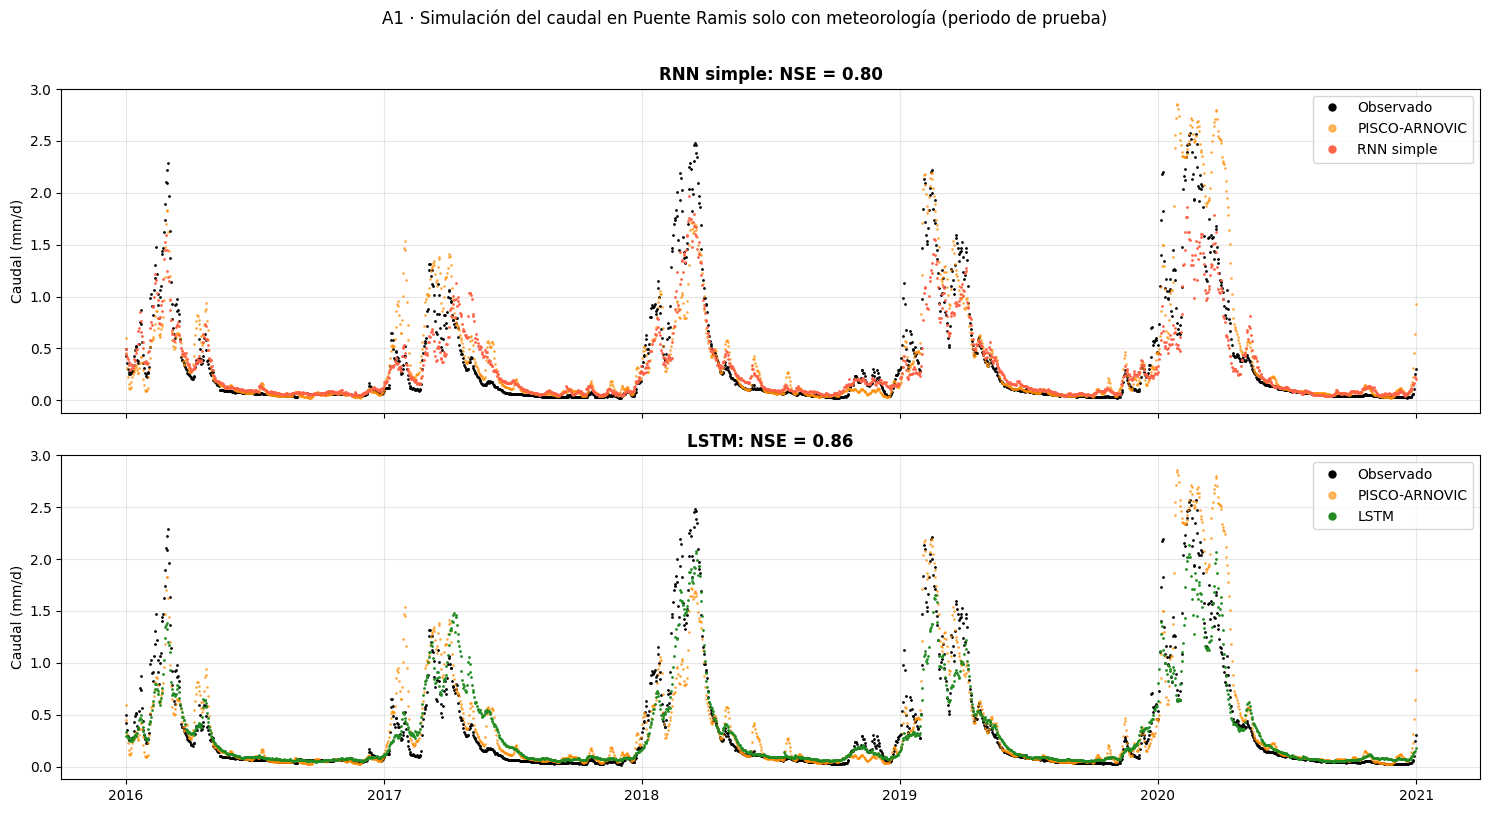

In [11]:
p = per_s['prueba']
obs_te = q_obs[ts][p]
sim_arnovic = df['flow_sim'].values[ts][p]
pred_rnn_sim = a_caudal(rnn_sim.predict(Xs[p], verbose=0).ravel())
pred_lstm_sim = a_caudal(lstm_sim.predict(Xs[p], verbose=0).ravel())

print(f"{'Modelo (prueba 2016–2020)':<28s} {'NSE':>6s} {'KGE':>6s} {'RMSE':>6s} {'MAE':>6s}")
print('-' * 56)
for nombre, pred in [('PISCO-ARNOVIC (hidrológico)', sim_arnovic),
                     ('RNN simple', pred_rnn_sim), ('LSTM', pred_lstm_sim)]:
    print(f"{nombre:<28s} {nse(obs_te, pred):6.3f} {kge(obs_te, pred):6.3f} {rmse(obs_te, pred):6.3f} {mae(obs_te, pred):6.3f}")
    filas_tabla.append({'Experimento': 'A1 · 180 d de meteorología → Q(t) (simulación)', 'Modelo': nombre,
                        'NSE': nse(obs_te, pred), 'KGE': kge(obs_te, pred),
                        'RMSE (mm/d)': rmse(obs_te, pred), 'MAE (mm/d)': mae(obs_te, pred)})

fig, ejes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
f = fechas_s[p]
for ax, pred, nombre, color in [(ejes[0], pred_rnn_sim, 'RNN simple', 'tomato'),
                                (ejes[1], pred_lstm_sim, 'LSTM', 'forestgreen')]:
    ax.plot(f, obs_te, 'k.', ms=2, label='Observado')
    ax.plot(f, sim_arnovic, '.', color='darkorange', ms=2, alpha=0.6, label='PISCO-ARNOVIC')
    ax.plot(f, pred, '.', color=color, ms=2, label=nombre)
    ax.set_ylabel('Caudal (mm/d)'); ax.set_title(f'{nombre}: NSE = {nse(obs_te, pred):.2f}', fontweight='bold')
    ax.legend(markerscale=5); ax.grid(alpha=0.3)
plt.suptitle('A1 · Simulación del caudal en Puente Ramis solo con meteorología (periodo de prueba)', y=1.01)
plt.tight_layout(); plt.show()

### Resultados e interpretación de A1

Los resultados registrados en `resultados_puente_ramis_multivariado.csv` para el periodo de prueba (2016–2020) son:

| Modelo | NSE | KGE | RMSE (mm/d) | MAE (mm/d) |
|---|---:|---:|---:|---:|
| PISCO-ARNOVIC | 0.697 | 0.799 | 0.290 | 0.143 |
| RNN simple | 0.762 | 0.686 | 0.257 | 0.147 |
| **LSTM** | **0.858** | **0.806** | **0.199** | **0.111** |

La LSTM obtuvo el mejor desempeño global: presentó el NSE y KGE más altos, además de los menores errores RMSE y MAE. En esta comparación, la LSTM representó mejor la variabilidad y magnitud del caudal observado que la RNN simple y PISCO-ARNOVIC.

**Lectura hidrológica:** el uso de una ventana meteorológica de 180 días permite que la red considere la precipitación y las condiciones atmosféricas antecedentes. La ventaja de la LSTM es coherente con su capacidad para conservar dependencias temporales de mayor duración.

> Los valores anteriores corresponden al CSV de resultados proporcionado para esta adaptación. Vuelve a ejecutar las celdas de entrenamiento para regenerar y confirmar las métricas en tu propio entorno antes de presentar los resultados como una reproducción computacional independiente.

## A2 · Pronóstico con asimilación del caudal observado

En un centro de pronóstico se dispone del caudal hasta el día de emisión. Se incorporan dos canales:

- `q_entrada`: log-caudal observado; cuando falta, se utiliza `flow_sim` como entrada auxiliar.
- `q_bandera`: 1 si el valor es observado y 0 si se utiliza el simulado.

El modelo predice el cambio Δ = log Q(t+H) − log Q(t). La persistencia equivale a predecir Δ = 0. Se evalúan horizontes de 1, 3 y 7 días.


In [12]:
q_entrada = np.log(df['flow_obs'].fillna(df['flow_sim']).values + 0.05)
q_entrada_n = (q_entrada - q_media) / q_desv
q_bandera = df['flow_obs'].notna().values.astype('float32')
X_pron = np.column_stack([X_met_n, q_entrada_n, q_bandera]).astype('float32')

VENTANA_PRON = 90
resultados_pron = {}
for H in [1, 3, 7]:
    Xp, tp, fechas_p, per_p = crear_ventanas(X_pron, VENTANA_PRON, horizonte=H)
    base = q_entrada_n[tp]                            # último caudal conocido (escala normalizada)
    yp = (q_n[tp + H] - base).astype('float32')       # objetivo: el CAMBIO hasta t+H
    print(f'Horizonte {H} días:')
    modelo_rnn, _ = entrenar(layers.SimpleRNN(32), Xp, yp, per_p)
    modelo, _ = entrenar(layers.LSTM(32), Xp, yp, per_p)

    p = per_p['prueba']
    obs = q_obs[tp + H][p]
    pred_rnn = a_caudal(modelo_rnn.predict(Xp[p], verbose=0).ravel() + base[p])
    pred = a_caudal(modelo.predict(Xp[p], verbose=0).ravel() + base[p])
    persist = a_caudal(base[p])
    resultados_pron[H] = {'fechas': fechas_p[p], 'obs': obs, 'RNN': pred_rnn, 'LSTM': pred, 'Persistencia': persist,
                          'PISCO-ARNOVIC': df['flow_sim'].values[tp + H][p]}

print(f"\n{'Horizonte':<10s} {'RNN':>7s} {'LSTM':>7s} {'Persist.':>9s} {'ARNOVIC':>8s}   (NSE, prueba 2016–2020)")
for H, r in resultados_pron.items():
    print(f"{H:>3d} días   " + ' '.join(f"{nse(r['obs'], r[m]):8.3f}" for m in ['RNN', 'LSTM', 'Persistencia', 'PISCO-ARNOVIC']))

Horizonte 1 días:
  SimpleRNN  40 épocas,  38.9 s
  LSTM       40 épocas,  92.7 s
Horizonte 3 días:
  SimpleRNN  40 épocas,  41.6 s
  LSTM       40 épocas,  92.5 s
Horizonte 7 días:
  SimpleRNN  25 épocas,  27.9 s
  LSTM       25 épocas,  52.9 s

Horizonte      RNN    LSTM  Persist.  ARNOVIC   (NSE, prueba 2016–2020)
  1 días      0.989    0.988    0.978    0.697
  3 días      0.951    0.950    0.887    0.697
  7 días      0.803    0.811    0.732    0.697


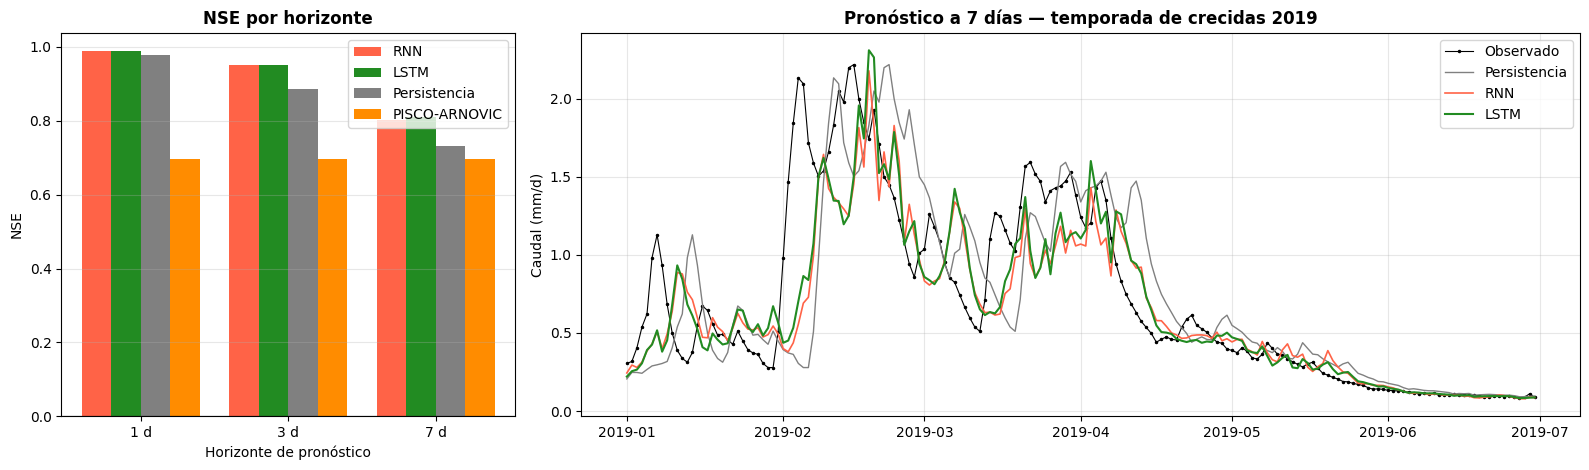

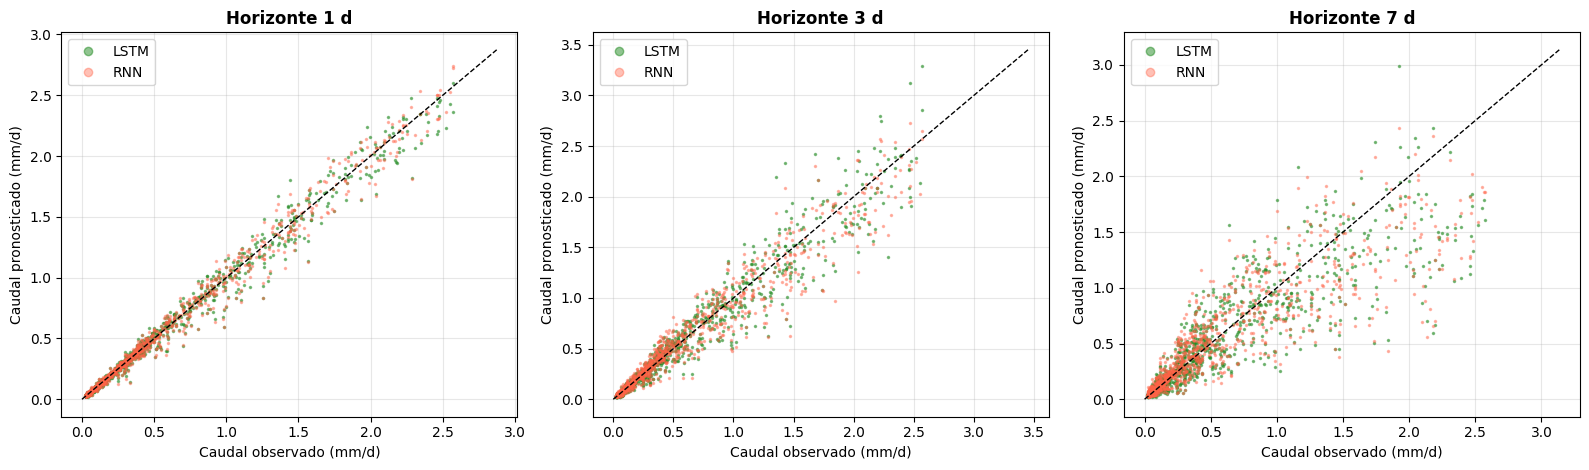

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 2.2]})
horizontes = list(resultados_pron)
ancho = 0.2
for k, (modelo_nombre, color) in enumerate([('RNN', 'tomato'), ('LSTM', 'forestgreen'), ('Persistencia', 'gray'),
                                            ('PISCO-ARNOVIC', 'darkorange')]):
    valores = [nse(resultados_pron[H]['obs'], resultados_pron[H][modelo_nombre]) for H in horizontes]
    ejes[0].bar(np.arange(len(horizontes)) + (k - 1.5) * ancho, valores, ancho, color=color, label=modelo_nombre)
ejes[0].axhline(0, color='k', lw=0.8)
ejes[0].set_xticks(range(len(horizontes))); ejes[0].set_xticklabels([f'{H} d' for H in horizontes])
ejes[0].set_xlabel('Horizonte de pronóstico'); ejes[0].set_ylabel('NSE')
ejes[0].set_title('NSE por horizonte', fontweight='bold'); ejes[0].legend(); ejes[0].grid(axis='y', alpha=0.3)

r = resultados_pron[7]
tramo = (r['fechas'] >= '2019-01-01') & (r['fechas'] <= '2019-06-30')
ejes[1].plot(r['fechas'][tramo], r['obs'][tramo], 'k.-', ms=3, lw=0.8, label='Observado')
ejes[1].plot(r['fechas'][tramo], r['Persistencia'][tramo], '-', color='gray', lw=1, label='Persistencia')
ejes[1].plot(r['fechas'][tramo], r['RNN'][tramo], '-', color='tomato', lw=1.2, label='RNN')
ejes[1].plot(r['fechas'][tramo], r['LSTM'][tramo], '-', color='forestgreen', lw=1.5, label='LSTM')
ejes[1].set_ylabel('Caudal (mm/d)'); ejes[1].legend(); ejes[1].grid(alpha=0.3)
ejes[1].set_title('Pronóstico a 7 días — temporada de crecidas 2019', fontweight='bold')
plt.tight_layout(); plt.show()

# Observado vs. pronosticado (periodo de prueba completo) para cada horizonte
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, H in zip(ejes, horizontes):
    r = resultados_pron[H]
    ax.plot(r['obs'], r['LSTM'], '.', ms=3, color='forestgreen', alpha=0.5, label='LSTM')
    ax.plot(r['obs'], r['RNN'], '.', ms=3, color='tomato', alpha=0.4, label='RNN')
    lim = max(r['obs'].max(), r['LSTM'].max(), r['RNN'].max()) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', lw=1)
    ax.set_xlabel('Caudal observado (mm/d)'); ax.set_ylabel('Caudal pronosticado (mm/d)')
    ax.set_title(f'Horizonte {H} d', fontweight='bold'); ax.legend(markerscale=4); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Resultados e interpretación de A2

Resultados consignados en el archivo CSV para los horizontes de pronóstico:

| Horizonte | Modelo | NSE | KGE | RMSE (mm/d) | MAE (mm/d) |
|---|---|---:|---:|---:|---:|
| 1 día | Persistencia | 0.978 | 0.989 | 0.077 | 0.035 |
| 1 día | RNN | **0.989** | **0.990** | **0.056** | 0.025 |
| 1 día | LSTM | 0.988 | 0.980 | 0.058 | 0.025 |
| 3 días | Persistencia | 0.887 | 0.943 | 0.177 | 0.082 |
| 3 días | RNN | **0.951** | 0.939 | 0.117 | 0.055 |
| 3 días | LSTM | 0.950 | **0.968** | 0.117 | **0.052** |
| 7 días | Persistencia | 0.732 | **0.866** | 0.273 | 0.130 |
| 7 días | RNN | 0.803 | 0.780 | 0.234 | 0.111 |
| 7 días | LSTM | **0.811** | 0.795 | **0.229** | **0.106** |

**Interpretación:**

- **1 día:** RNN alcanza el NSE más alto (0.989), con desempeño muy próximo al de LSTM y persistencia.
- **3 días:** RNN obtiene el NSE ligeramente mayor (0.951), mientras LSTM presenta el KGE más alto (0.968) y menor MAE.
- **7 días:** LSTM presenta el mejor NSE (0.811) y los menores errores; ambas redes superan a la persistencia en NSE.
- El NSE disminuye conforme aumenta el horizonte, lo que refleja la mayor dificultad de anticipar la evolución del caudal a varios días.

**Precaución de comparación:** en el CSV entregado, los indicadores de PISCO-ARNOVIC se repiten exactamente en los tres horizontes. Por ello, se deben tratar como una referencia reportada y verificar su cálculo por horizonte al volver a ejecutar el notebook; no se interpretan como tres evaluaciones independientes confirmadas.


### Tabla comparativa de resultados (Puente Ramis)

La tabla dinámica de la siguiente celda recalcula NSE, KGE, RMSE y MAE a partir de las predicciones generadas durante la ejecución del notebook. El archivo `resultados_puente_ramis_multivariado.csv` contiene los resultados facilitados para esta adaptación y se incluye también en el repositorio como registro de referencia.

In [14]:
# Tabla comparativa final (periodo de prueba 2016–2020, solo días con caudal observado)
for H, r in resultados_pron.items():
    for nombre in ['PISCO-ARNOVIC', 'Persistencia', 'RNN', 'LSTM']:
        filas_tabla.append({'Experimento': f'A2 · 90 d de meteorología + caudal → +{H} d (cambio Δ)', 'Modelo': nombre,
                            'NSE': nse(r['obs'], r[nombre]), 'KGE': kge(r['obs'], r[nombre]),
                            'RMSE (mm/d)': rmse(r['obs'], r[nombre]), 'MAE (mm/d)': mae(r['obs'], r[nombre])})

tabla_final = pd.DataFrame(filas_tabla).set_index(['Experimento', 'Modelo']).round(3)
tabla_final.to_csv('resultados_puente_ramis_multivariado.csv')
tabla_final

NSE  \
Experimento                                        Modelo                               
A1 · 180 d de meteorología → Q(t) (simulación)     PISCO-ARNOVIC (hidrológico)  0.697   
                                                   RNN simple                   0.804   
                                                   LSTM                         0.858   
A2 · 90 d de meteorología + caudal → +1 d (camb... PISCO-ARNOVIC                0.697   
                                                   Persistencia                 0.978   
                                                   RNN                          0.989   
                                                   LSTM                         0.988   
A2 · 90 d de meteorología + caudal → +3 d (camb... PISCO-ARNOVIC                0.697   
                                                   Persistencia                 0.887   
                                                   RNN                          0.951   
                                                   LSTM                         0.950   
A2 · 90 d de meteorología + caudal → +7 d (camb... PISCO-ARNOVIC                0.697   
                                                   Persistencia                 0.732   
                                                   RNN                          0.803   
                                                   LSTM                         0.811   

                                                                                  KGE  \
Experimento                                        Modelo                               
A1 · 180 d de meteorología → Q(t) (simulación)     PISCO-ARNOVIC (hidrológico)  0.799   
                                                   RNN simple                   0.668   
                                                   LSTM                         0.806   
A2 · 90 d de meteorología + caudal → +1 d (camb... PISCO-ARNOVIC                0.799   
                                                   Persistencia                 0.989   
                                                   RNN                          0.990   
                                                   LSTM                         0.980   
A2 · 90 d de meteorología + caudal → +3 d (camb... PISCO-ARNOVIC                0.799   
                                                   Persistencia                 0.943   
                                                   RNN                          0.939   
                                                   LSTM                         0.968   
A2 · 90 d de meteorología + caudal → +7 d (camb... PISCO-ARNOVIC                0.799   
                                                   Persistencia                 0.866   
                                                   RNN                          0.780   
                                                   LSTM                         0.795   

                                                                                RMSE (mm/d)  \
Experimento                                        Modelo                                     
A1 · 180 d de meteorología → Q(t) (simulación)     PISCO-ARNOVIC (hidrológico)        0.290   
                                                   RNN simple                         0.233   
                                                   LSTM                               0.199   
A2 · 90 d de meteorología + caudal → +1 d (camb... PISCO-ARNOVIC                      0.290   
                                                   Persistencia                       0.077   
                                                   RNN                                0.056   
                                                   LSTM                               0.058   
A2 · 90 d de meteorología + caudal → +3 d (camb... PISCO-ARNOVIC                      0.290   
                                                   Persistencia                       0.177   
         

## Conclusiones para Puente Ramis (cuenca del Titicaca)

### Datos y metodología

Se integraron las series diarias de la estación hidrométrica Puente Ramis (`PE_47251282`) de CAMELS-PE. El periodo común de los archivos es 1981–2025 (16 436 registros diarios). La serie de caudal observado (`flow_obs`) comienza el 1 de septiembre de 1991 y presenta días sin observación. Las variables meteorológicas empleadas en los modelos son precipitación (`prec`), temperatura media (`tmean`), temperatura máxima (`tmax`), temperatura mínima (`tmin`), radiación solar (`srad`) y presión de vapor (`vprp`). La ETP se conserva en la base integrada, pero no se utiliza como predictor para mantener las seis entradas de la práctica original.

La evaluación se mantiene en una partición cronológica: entrenamiento 1998–2010, validación 2011–2015 y prueba 2016–2020. La normalización se calcula con el periodo de entrenamiento. Los días sin caudal observado no se utilizan como objetivos supervisados; `flow_sim` se emplea únicamente como canal auxiliar de entrada en A2 cuando falta `flow_obs`.

### Hallazgos principales

1. **A1 — Simulación con meteorología:** según el CSV de resultados proporcionado, la LSTM obtuvo el mejor desempeño (NSE = 0.858; KGE = 0.806; RMSE = 0.199 mm/d; MAE = 0.111 mm/d). Esto sugiere que la memoria controlada de la LSTM ayuda a representar la relación temporal entre las condiciones meteorológicas antecedentes y el caudal.
2. **A2 — Pronóstico con caudal reciente:** los resultados consignados muestran un desempeño alto a un día (NSE de 0.989 para RNN y 0.988 para LSTM). Al ampliar el horizonte a siete días, el NSE disminuye; la LSTM obtiene el mejor NSE de ese horizonte (0.811), frente a 0.803 de RNN y 0.732 de persistencia.
3. **Comparación de arquitecturas:** no existe un ganador único para todos los horizontes. La RNN destaca ligeramente en NSE a uno y tres días, mientras que la LSTM presenta ventajas en KGE a tres días y en NSE/errores a siete días.

### Limitaciones y reproducibilidad

Los indicadores incluidos en el archivo CSV son resultados proporcionados para esta adaptación y deben contrastarse con una ejecución completa del notebook. En particular, los valores de PISCO-ARNOVIC aparecen repetidos para los tres horizontes de A2, por lo que deben verificarse antes de atribuirles una interpretación específica por horizonte. El periodo de prueba termina en 2020; los datos posteriores no forman parte de esta comparación.

**Conclusión general:** la memoria temporal es relevante para la modelación lluvia–escorrentía en Puente Ramis. La LSTM muestra una ventaja clara en A1 y a siete días en A2, mientras que la RNN puede ser competitiva en pronósticos de corto plazo. La incorporación del caudal reciente mejora la información disponible para el pronóstico, aunque la incertidumbre aumenta con el horizonte temporal.


# 4B. Práctica B: experimento de memoria lluvia–caudal

Construimos un problema donde sabemos **exactamente** cuánta memoria se necesita.

**Escenario:** en una cuenca altoandina, el caudal base de hoy depende de la lluvia que **recargó el acuífero** durante una ventana de 5 días. Generamos secuencias de 30 días de lluvia (ruido aleatorio) y dos tareas:

| Tarea | El objetivo depende de... | Memoria necesaria |
|---|---|---|
| **Corta** | lluvia media de los **últimos 5 días** (días 26–30) | ~5 pasos |
| **Larga** | lluvia media de los **primeros 5 días** (días 1–5) | ~30 pasos |

El modelo ve exactamente los mismos datos; solo cambia **dónde** está la información. Una línea base que siempre predice el promedio tiene MSE ≈ 0.017; un modelo perfecto, MSE ≈ 0.

In [15]:
rng = np.random.default_rng(1)
N_SEQ, LARGO = 3000, 30
lluvia = rng.uniform(0, 1, (N_SEQ, LARGO, 1)).astype('float32')
y_corta = lluvia[:, -5:, 0].mean(axis=1)    # depende de los últimos 5 días
y_larga = lluvia[:, :5, 0].mean(axis=1)     # depende de los primeros 5 días

mse_base = np.var(y_larga)
print(f"MSE de la línea base (predecir siempre el promedio): {mse_base:.4f}")

def experimento(capa, y_obj):
    keras.utils.set_random_seed(0)
    m = keras.Sequential([keras.Input(shape=(LARGO, 1)), capa, layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(0.003), loss='mse')
    h = m.fit(lluvia[:2400], y_obj[:2400], epochs=30, batch_size=64,
              validation_data=(lluvia[2400:], y_obj[2400:]), verbose=0)
    return h.history['val_loss']

t0 = time.time()
resultados = {}
for tarea, y_obj in [('Corta', y_corta), ('Larga', y_larga)]:
    for nombre, capa in [('RNN', lambda: layers.SimpleRNN(16)), ('LSTM', lambda: layers.LSTM(16))]:
        resultados[(tarea, nombre)] = experimento(capa(), y_obj)
        print(f"Tarea {tarea:<5s} | {nombre:<4s}: MSE validación final = {resultados[(tarea, nombre)][-1]:.4f}")
print(f"Tiempo total: {time.time() - t0:.0f} s")

MSE de la línea base (predecir siempre el promedio): 0.0175
Tarea Corta | RNN : MSE validación final = 0.0001
Tarea Corta | LSTM: MSE validación final = 0.0009
Tarea Larga | RNN : MSE validación final = 0.0174
Tarea Larga | LSTM: MSE validación final = 0.0028
Tiempo total: 66 s


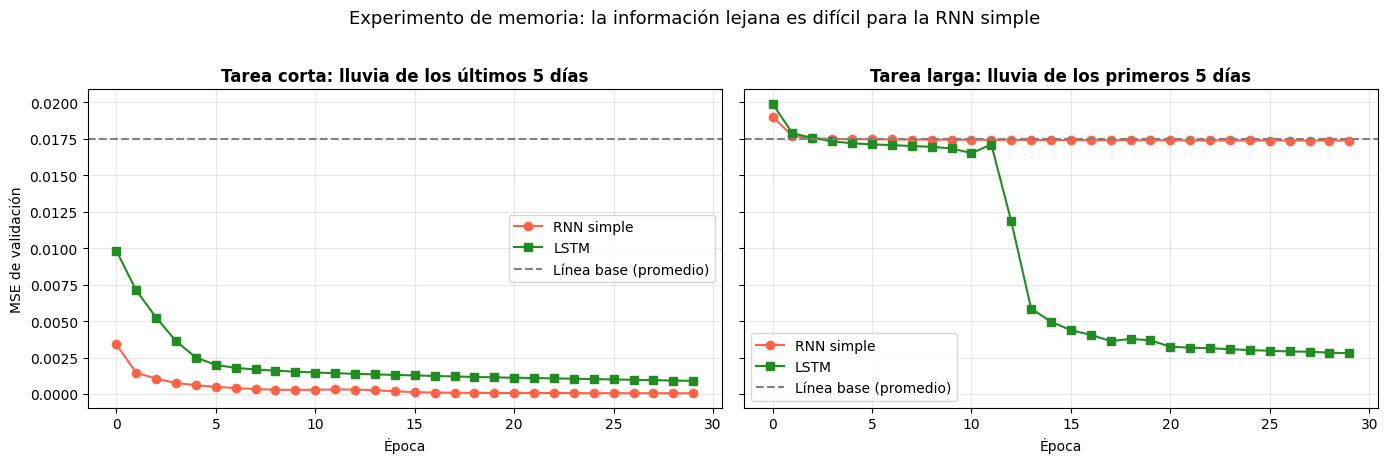

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, tarea in zip(ejes, ['Corta', 'Larga']):
    ax.plot(resultados[(tarea, 'RNN')], 'o-', color='tomato', label='RNN simple')
    ax.plot(resultados[(tarea, 'LSTM')], 's-', color='forestgreen', label='LSTM')
    ax.axhline(mse_base, ls='--', color='gray', label='Línea base (promedio)')
    ax.set_title(f'Tarea {tarea.lower()}: lluvia de los '
                 f"{'últimos' if tarea == 'Corta' else 'primeros'} 5 días", fontweight='bold')
    ax.set_xlabel('Época'); ax.grid(alpha=0.3); ax.legend()
ejes[0].set_ylabel('MSE de validación')
plt.suptitle('Experimento de memoria: la información lejana es difícil para la RNN simple', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

**Interpretación:** en la tarea corta ambas redes aprenden. En la tarea larga, la RNN simple se queda cerca de la línea base (no logra "recordar" 25 días atrás: gradiente desvaneciente), mientras la LSTM aprende a **mantener la información en su estado de celda** ($f_t \approx 1$) hasta el final. Observa que la LSTM pasa varias épocas estancada y de pronto "descubre" la dependencia lejana: la caída brusca de la curva es típica de este tipo de aprendizaje.

Esta es la razón por la que las LSTM se volvieron el estándar en hidrología: Kratzert et al. (2018) mostraron que una LSTM supera a modelos hidrológicos conceptuales para simular caudales en cientos de cuencas, porque aprende la memoria de la nieve, el suelo y los acuíferos. Esta intuición se relaciona con la memoria hidrológica que se estudia en la Práctica A con **Puente Ramis (CAMELS-PE)**.

# 5. Atención: dejar que el modelo decida en qué fijarse

### El problema de la memoria secuencial

La LSTM mejora a la RNN con memoria controlada, pero tiene un límite fundamental: **todo el pasado se comprime en un único vector de estado oculto** de tamaño fijo (32 o 64 números), sin importar cuán larga sea la secuencia.

Piensa en pronosticar la temperatura mínima de mañana en **Puerto Maldonado**. Pistas útiles:
- la temperatura de ayer (1 día atrás),
- un **friaje** (masa de aire frío del sur) que llegó hace 3 días,
- la misma fecha del año pasado (~365 días atrás).

En una LSTM, todo debe caber en un vector. El modelo no puede "volver a mirar" selectivamente el día del friaje.

**¿Y si el modelo pudiera mirar toda la secuencia y decidir, para cada predicción, qué días pasados importan más?** Esa es la idea de la **atención**.

### La atención paso a paso

Supongamos 5 días y queremos predecir el día 6. Para cada día pasado preguntamos *"¿qué tan relevante es para predecir el día 6?"*:

1. **Puntuar:** calcular un puntaje de relevancia para cada día.
2. **Ponderar:** convertir los puntajes en pesos que suman 1 (con *softmax*).
3. **Combinar:** promedio ponderado de la información de cada día → **vector de contexto**.

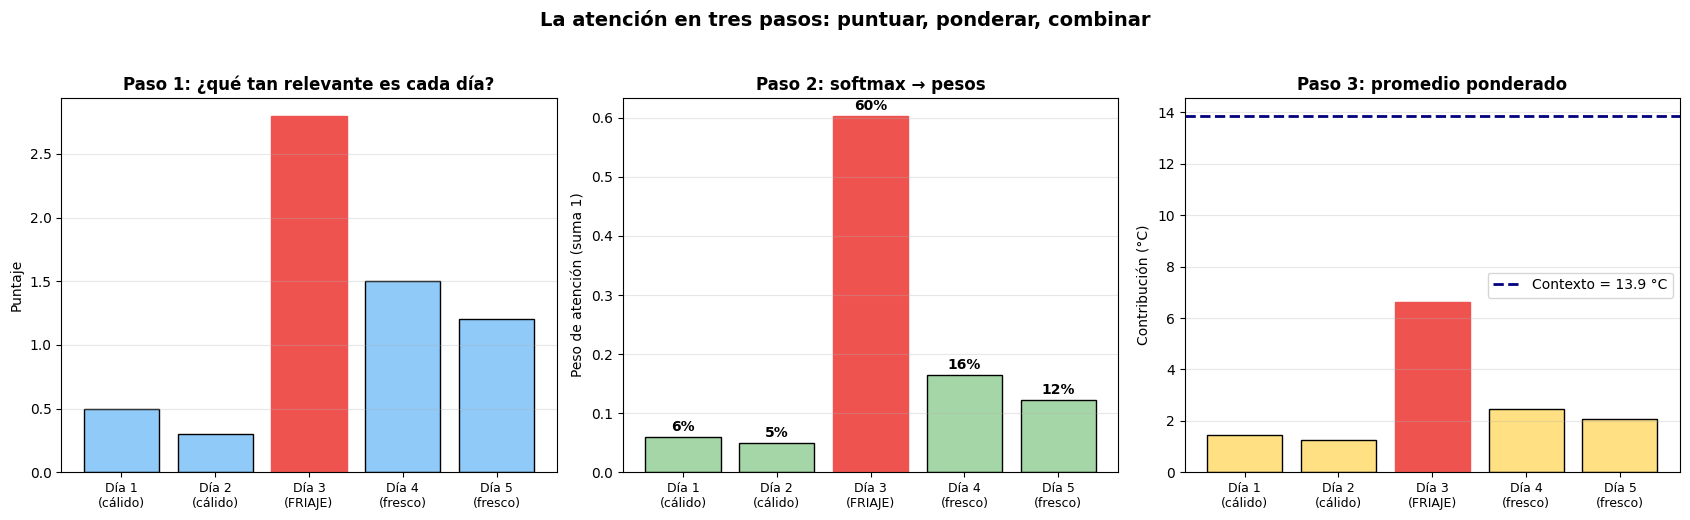

Pesos: {'Día 1': '6.1%', 'Día 2': '5.0%', 'Día 3': '60.4%', 'Día 4': '16.4%', 'Día 5': '12.2%'}
Contexto: 13.9 °C  (dominado por el friaje del día 3)


In [17]:
dias_txt = ['Día 1\n(cálido)', 'Día 2\n(cálido)', 'Día 3\n(FRIAJE)', 'Día 4\n(fresco)', 'Día 5\n(fresco)']
temps = np.array([24, 25, 11, 15, 17])   # temperatura mínima (°C), Puerto Maldonado

# Paso 1: puntajes de relevancia (en un modelo real se calculan; aquí los fijamos a mano)
puntajes = np.array([0.5, 0.3, 2.8, 1.5, 1.2])

# Paso 2: softmax convierte puntajes en pesos que suman 1
def softmax(x, eje=-1):
    e = np.exp(x - np.max(x, axis=eje, keepdims=True))   # restar el máximo: estabilidad numérica
    return e / e.sum(axis=eje, keepdims=True)

pesos = softmax(puntajes)

# Paso 3: promedio ponderado = vector de contexto
contexto = np.sum(pesos * temps)

fig, ejes = plt.subplots(1, 3, figsize=(17, 5))
for ax, valores, color, titulo, etiqueta_y in [
        (ejes[0], puntajes, '#90CAF9', 'Paso 1: ¿qué tan relevante es cada día?', 'Puntaje'),
        (ejes[1], pesos, '#A5D6A7', 'Paso 2: softmax → pesos', 'Peso de atención (suma 1)'),
        (ejes[2], pesos * temps, '#FFE082', 'Paso 3: promedio ponderado', 'Contribución (°C)')]:
    barras = ax.bar(range(5), valores, color=color, edgecolor='black')
    barras[2].set_color('#EF5350')
    ax.set_xticks(range(5)); ax.set_xticklabels(dias_txt, fontsize=9)
    ax.set_title(titulo, fontweight='bold'); ax.set_ylabel(etiqueta_y); ax.grid(axis='y', alpha=0.3)
for j, w in enumerate(pesos):
    ejes[1].text(j, w + 0.01, f'{w:.0%}', ha='center', fontweight='bold')
ejes[2].axhline(contexto, color='navy', ls='--', lw=2, label=f'Contexto = {contexto:.1f} °C')
ejes[2].legend()
plt.suptitle('La atención en tres pasos: puntuar, ponderar, combinar', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout(); plt.show()

print("Pesos:", {f'Día {i+1}': f'{w:.1%}' for i, w in enumerate(pesos)})
print(f"Contexto: {contexto:.1f} °C  (dominado por el friaje del día 3)")

### ¿Qué acaba de pasar?

1. **Puntuar:** cada día recibió un número que mide su relevancia. El día 3 (friaje) obtuvo el mayor.
2. **Ponderar:** el softmax convirtió los puntajes en pesos positivos que suman 1. El friaje recibe ~60% de la atención.
3. **Combinar:** el promedio ponderado produce un vector de contexto dominado por el friaje.

Ese es *todo* el mecanismo de atención. Lo demás es **cómo se calculan los puntajes**.

## 5.1 Query, Key y Value: cómo se calculan los puntajes

En una red real, los puntajes se calculan comparando **representaciones vectoriales aprendidas**. Se usan tres vectores por posición, con nombres tomados de la búsqueda en bases de datos.

**Analogía: el catálogo de la biblioteca del SENAMHI.** Buscas información sobre *"friajes que afectan cultivos en la selva sur"*:

- Tu **Query** es lo que buscas: "friaje + selva sur + agricultura".
- Cada documento tiene una **Key** (su ficha de catálogo): "Climatología de friajes en Madre de Dios", "Heladas en el altiplano", "Rendimiento de cacao y clima"...
- Comparas tu Query con cada Key: unas coinciden mucho (puntaje alto), otras no.
- De los documentos que coinciden, lees su contenido, el **Value**, y lo combinas.

En la **auto-atención** (*self-attention*), cada posición de la secuencia es a la vez quien busca y un documento del catálogo:

| Vector | Rol | En la biblioteca |
|---|---|---|
| **Query ($Q$)** | "¿Qué estoy buscando?" | Tus términos de búsqueda |
| **Key ($K$)** | "¿Qué contengo?" | La ficha de catálogo |
| **Value ($V$)** | "¿Qué información aporto si me eligen?" | El contenido del documento |

El puntaje entre las posiciones $i$ y $j$ es el **producto punto** $Q_i \cdot K_j$: alto si apuntan en direcciones parecidas.

### La fórmula de la atención

$$\text{Atención}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

donde $d_k$ es la dimensión de las Keys (el escalado evita productos punto demasiado grandes). **No hace falta memorizarla**: *comparar, ponderar, combinar.*

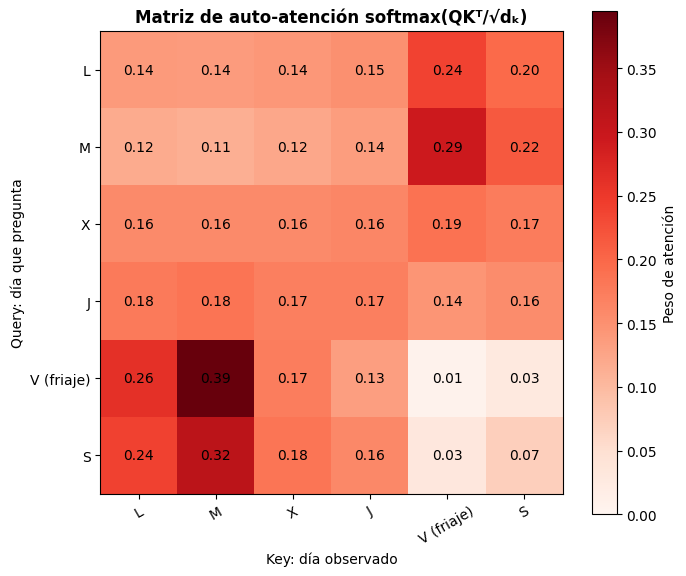

Forma de Q, K, V: (6, 4)  |  matriz de atención: (6, 6)  |  salida: (6, 4)
Cada fila suma: [1. 1. 1. 1. 1. 1.]


In [18]:
# Auto-atención con NumPy sobre 6 días: cada día "mira" a todos los demás
rng = np.random.default_rng(3)
dias6 = ['L', 'M', 'X', 'J', 'V (friaje)', 'S']
# Representación de cada día: [temperatura normalizada, viento del sur, humedad]
E = np.array([[ 0.8, 0.1, 0.7],
              [ 0.9, 0.0, 0.8],
              [ 0.7, 0.2, 0.6],
              [ 0.6, 0.3, 0.6],
              [-0.9, 1.0, 0.2],     # friaje: frío, viento sur fuerte, seco
              [-0.4, 0.6, 0.4]])

d_k = 4
W_Q, W_K, W_V = (rng.normal(0, 1, (3, d_k)) for _ in range(3))   # en la práctica se APRENDEN
Q, K, V = E @ W_Q, E @ W_K, E @ W_V

puntajes = Q @ K.T / np.sqrt(d_k)       # (6, 6): cada fila = un día comparándose con todos
A = softmax(puntajes, eje=1)            # cada fila suma 1
salida = A @ V                          # nueva representación de cada día (6, d_k)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(A, cmap='Reds', vmin=0, vmax=A.max())
for i in range(6):
    for j in range(6):
        ax.text(j, i, f'{A[i, j]:.2f}', ha='center', va='center', fontsize=10)
ax.set_xticks(range(6)); ax.set_xticklabels(dias6, rotation=30)
ax.set_yticks(range(6)); ax.set_yticklabels(dias6)
ax.set_xlabel('Key: día observado'); ax.set_ylabel('Query: día que pregunta')
ax.set_title('Matriz de auto-atención softmax(QKᵀ/√dₖ)', fontweight='bold')
plt.colorbar(im, ax=ax, label='Peso de atención')
plt.tight_layout(); plt.show()

print(f"Forma de Q, K, V: {Q.shape}  |  matriz de atención: {A.shape}  |  salida: {salida.shape}")
print("Cada fila suma:", A.sum(axis=1).round(3))

Con pesos aleatorios los patrones son arbitrarios; durante el entrenamiento, $W_Q$, $W_K$ y $W_V$ se ajustan para que cada día atienda a los días que **realmente** le ayudan a predecir.

### Por qué la atención resuelve el problema de largo alcance

En una RNN, la información del día 1 debe atravesar los días 2, 3, 4... para llegar al día 100; cada salto la degrada. Con atención, el día 100 **calcula directamente un producto punto con el día 1**, en un solo paso, sin importar la distancia. Además, todas las posiciones se procesan **en paralelo** (las RNN son secuenciales), lo que permite entrenar en GPU con enormes cantidades de datos.

# 6. Transformers: atención apilada en un modelo profundo

Un **Transformer** (Vaswani et al., 2017) es una red construida alrededor de la auto-atención. En lugar de procesar los tokens uno por uno, permite que **todos se atiendan entre sí en paralelo**.

> **Analogía (un comité de resaltadores).** Una capa de atención es un lector que decide qué resaltar. Un Transformer apila muchos lectores (varias *cabezas* por capa, muchas *capas*). Cada lector se especializa: uno sigue la gramática, otro el tema, otro las referencias lejanas.

Un bloque Transformer repite:

| Componente | Función |
|---|---|
| Embedding de tokens / parches | Convertir entradas en vectores |
| Codificación posicional | Inyectar el orden (la atención por sí sola no sabe qué va primero) |
| Auto-atención (multi-cabeza) | Cada token se compara con todos los demás |
| Capa feed-forward | Transformar el vector de cada posición |
| Conexión residual + LayerNorm | Mantener entrenables las redes profundas |

### Tres variantes

| Variante | Uso típico | Ejemplo |
|---|---|---|
| **Solo encoder** | Comprender / clasificar | BERT, Vision Transformer (ViT) |
| **Solo decoder** | Generar paso a paso | GPT, Claude (modelos de lenguaje) |
| **Encoder–decoder** | Convertir una secuencia en otra | Traducción, resumen |

### Más allá del texto

La atención se aplica a *cualquier* dato que pueda convertirse en un conjunto de vectores:

- **Vision Transformers:** la imagen se divide en parches; cada parche es un token.
- **Transformers de series de tiempo:** cada paso o ventana es un token.
- **Modelos fundacionales del clima y la Tierra:** GraphCast y Pangu-Weather (pronóstico global), Prithvi (NASA–IBM, imágenes HLS). Imágenes satelitales, variables climáticas y mapas de cobertura pueden "tokenizarse".

En Keras, la capa `layers.MultiHeadAttention` implementa la auto-atención; un Transformer pequeño para series de tiempo se construye con unas pocas líneas.

# 7. Elegir la arquitectura según la estructura de los datos

Una buena elección de modelo empieza por la **estructura de los datos** y el **objetivo** de la tarea:

| Datos / tarea | Estructura natural | Modelos habituales | Ejemplo peruano |
|---|---|---|---|
| Datos ambientales tabulares | filas y columnas | Random Forest, XGBoost, ANN densa | Calidad de agua (OEFA), atributos de cuencas |
| Imágenes | grilla espacial | CNN, U-Net, Vision Transformer | Deforestación en Madre de Dios (Sentinel-2) |
| Series de tiempo | secuencia ordenada | RNN, LSTM, CNN temporal, Transformer | Caudales del Rímac, temperatura SENAMHI, PM2.5 en Lima |
| Texto | secuencia de tokens | Transformer, LLM | Clasificar boletines y reportes de emergencias (INDECI) |
| Secuencia → secuencia | serie de entrada → serie de salida | Encoder–decoder LSTM o Transformer | Pronóstico de caudal de los próximos 7 días |
| Datos con muchas categorías | IDs discretos | Embeddings + modelo | Código de estación, tipo de suelo, especie |
| Multimodal | varios tipos de datos | Encoders separados + fusión | Imagen satelital + serie climática para rendimiento de cultivos |

**No existe una arquitectura mejor para todos los problemas.** Empieza siempre con una línea base simple (persistencia, RF) y añade complejidad solo si mejora la evaluación fuera de muestra.

---
## 🔬 Ejercicios

1. **Memoria de la cuenca (A1).** Repite la simulación con `VENTANA_SIM = 30`, `90` y `365`. ¿Cómo cambia el NSE? ¿Qué te dice eso sobre el tiempo de respuesta de la cuenca del Ramis?
2. **Ingeniería de características + LSTM (A1).** Añade a `VARS_MET` las características cíclicas `sin`/`cos` del día del año (sección 1.1) o la variable `prec_var`. ¿Mejora la LSTM? Recuerda que la LSTM ya *aprende* sus propias representaciones.
3. **Ensamble (A1).** Entrena la LSTM con 3 semillas distintas (`keras.utils.set_random_seed`) y promedia las predicciones. ¿Es más estable el NSE?
4. **Horizonte (A2).** Pronostica a **14 días**. ¿Sigue la LSTM superando a la persistencia? Prueba también a predecir el caudal directamente (sin el truco del cambio Δ): ¿qué ocurre a 1 día?
5. **Otra cuenca (opcional).** Si tienes acceso a la carpeta CAMELS-PE completa, carga el CSV de otra estación (lista en `01_metadata/stations.csv`), por ejemplo una de la vertiente del Atlántico. ¿Funciona igual la LSTM? ¿Y PISCO-ARNOVIC?
6. **Experimento de memoria.** Aumenta `LARGO` a 50. ¿Sigue aprendiendo la LSTM con 30 épocas? ¿Y con 80 épocas o con `layers.LSTM(32)`? Prueba también `layers.GRU(16)` (una variante simplificada de la LSTM).
7. **Nivel del lago Titicaca** (celdas siguientes). La solución propuesta pronostica el nivel **30 días adelante** con una ventana de 60 días. ¿Por qué un lago necesita ventanas más largas que un río como el Majes? Prueba `HORIZONTE = 1`: ¿por qué ahí la persistencia es casi imbatible?
8. **Conceptual.** Elige un problema ambiental del Perú que te interese y justifica qué arquitectura usarías según la tabla de la sección 7.

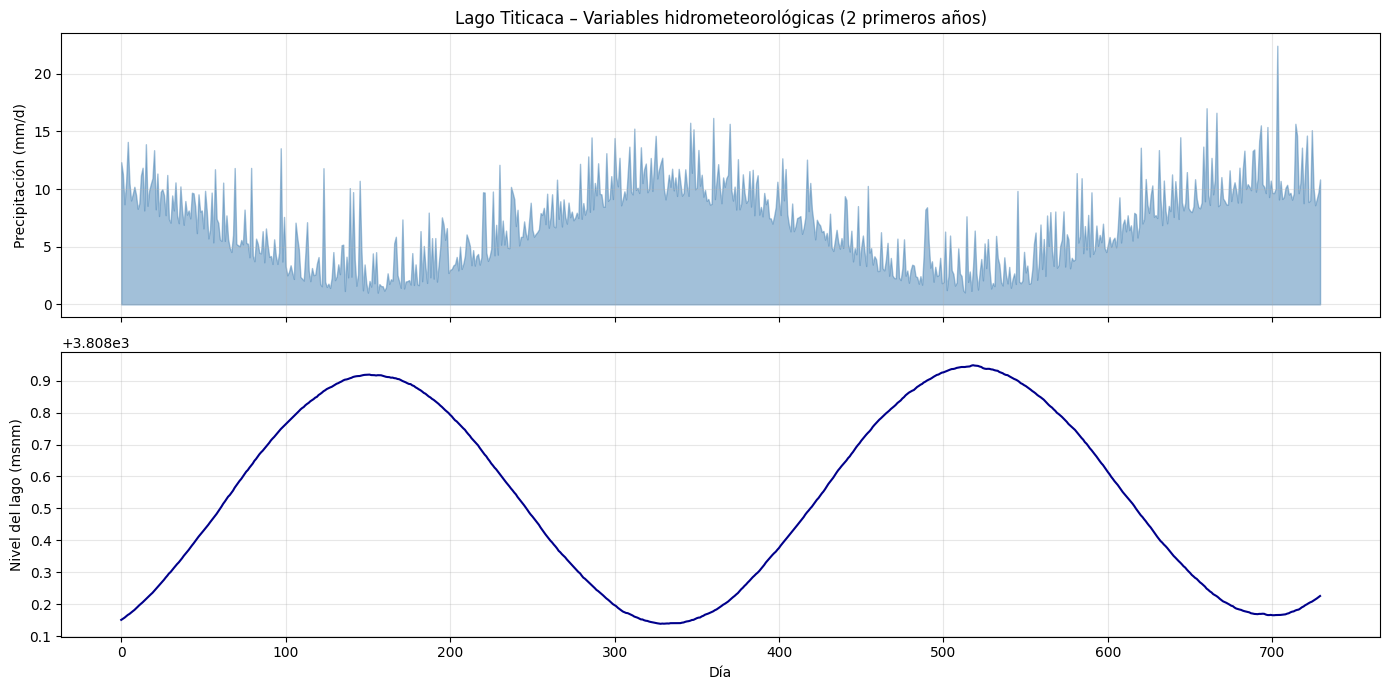

In [19]:
# Ejercicio 7 — Dataset sintético del Lago Titicaca (nivel en msnm)
np.random.seed(42)
n_dias_tt = 3650  # 10 años de datos
t_tt = np.arange(n_dias_tt)

ciclo_anual = np.sin(2 * np.pi * (t_tt - 60) / 365)          # máximo ~abril (después de lluvias)
tendencia = 0.0001 * t_tt
ruido_lento = np.convolve(np.random.normal(0, 0.05, n_dias_tt), np.ones(90) / 90, mode='same')
nivel_lago = 3808.5 + 0.4 * ciclo_anual + tendencia + ruido_lento
precip_tt = np.maximum(0, 3 + 4 * (-ciclo_anual + 0.5) + np.random.exponential(2, n_dias_tt))

fig, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ejes[0].fill_between(t_tt[:730], precip_tt[:730], alpha=0.5, color='steelblue')
ejes[0].set_ylabel('Precipitación (mm/d)')
ejes[0].set_title('Lago Titicaca – Variables hidrometeorológicas (2 primeros años)')
ejes[1].plot(t_tt[:730], nivel_lago[:730], color='darkblue', linewidth=1.5)
ejes[1].set_ylabel('Nivel del lago (msnm)'); ejes[1].set_xlabel('Día')
for ax in ejes:
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Persistencia : R² = 0.7347   RMSE = 14.44 cm
LSTM (+30 d) : R² = 0.9947   RMSE = 2.04 cm


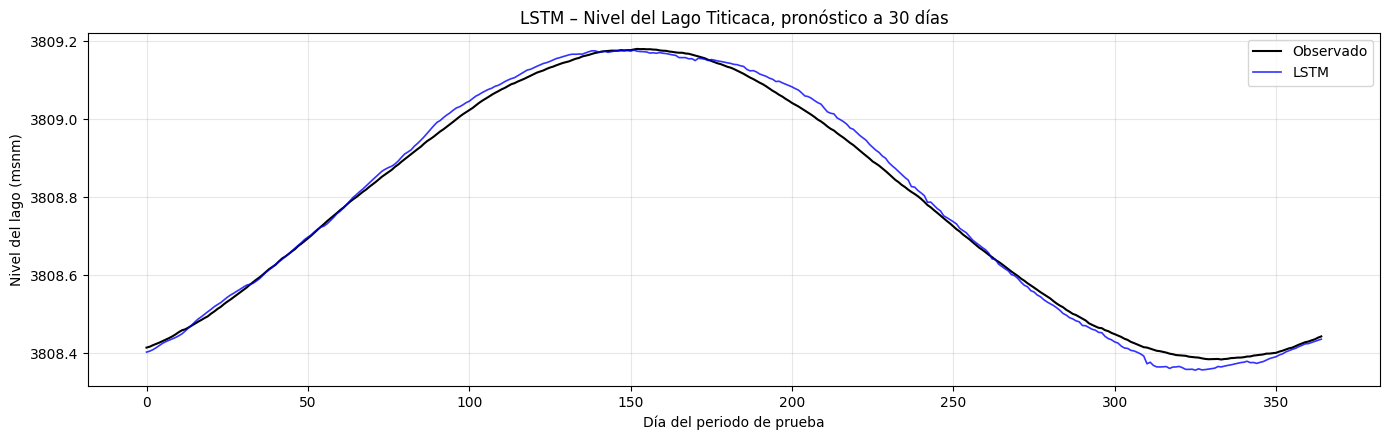

In [20]:
# Ejercicio 7 — Solución propuesta: LSTM con ventana de 60 días, pronóstico a 30 días
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error

datos_tt = np.column_stack([precip_tt, nivel_lago])
corte_tt = int(0.7 * len(datos_tt))
esc_tt = MinMaxScaler().fit(datos_tt[:corte_tt])
datos_tt_e = esc_tt.transform(datos_tt).astype('float32')

VENTANA_TT, HORIZONTE = 60, 30
n_ventanas = len(datos_tt_e) - VENTANA_TT - HORIZONTE + 1
X_tt = np.stack([datos_tt_e[i:i + VENTANA_TT] for i in range(n_ventanas)])
y_tt = datos_tt_e[VENTANA_TT + HORIZONTE - 1:, 1]     # objetivo = nivel del lago dentro de 30 días
n_tr_tt = corte_tt - VENTANA_TT - HORIZONTE + 1
X_tr_tt, X_te_tt = X_tt[:n_tr_tt], X_tt[n_tr_tt:]
y_tr_tt, y_te_tt = y_tt[:n_tr_tt], y_tt[n_tr_tt:]

keras.utils.set_random_seed(42)
lstm_tt = keras.Sequential([keras.Input(shape=(VENTANA_TT, 2)), layers.LSTM(32), layers.Dense(1)])
lstm_tt.compile(optimizer='adam', loss='mse')
lstm_tt.fit(X_tr_tt, y_tr_tt, epochs=20, batch_size=64, validation_split=0.1, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])

def desescalar_nivel(v):
    return v * esc_tt.data_range_[1] + esc_tt.data_min_[1]

y_te_real = desescalar_nivel(y_te_tt)
y_pred_tt = desescalar_nivel(lstm_tt.predict(X_te_tt, verbose=0).flatten())
y_persist_tt = desescalar_nivel(X_te_tt[:, -1, 1])

for nombre, pred in [('Persistencia', y_persist_tt), (f'LSTM (+{HORIZONTE} d)', y_pred_tt)]:
    print(f"{nombre:<13s}: R² = {r2_score(y_te_real, pred):.4f}   "
          f"RMSE = {np.sqrt(mean_squared_error(y_te_real, pred)) * 100:.2f} cm")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y_te_real[:365], 'k-', lw=1.5, label='Observado')
ax.plot(y_pred_tt[:365], 'b-', lw=1.2, alpha=0.8, label='LSTM')
ax.set_xlabel('Día del periodo de prueba'); ax.set_ylabel('Nivel del lago (msnm)')
ax.set_title(f'LSTM – Nivel del Lago Titicaca, pronóstico a {HORIZONTE} días'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## Resumen

| Concepto | Conclusión clave |
|---|---|
| Codificar → representar → decodificar | Estructura común a todo flujo de ML, del Random Forest a los LLM |
| Ingeniería de características | Un encoder **manual**: seno/coseno estacional, rezagos, acumulados |
| Embedding | Un encoder **aprendido** para categorías; categorías similares quedan cerca |
| RNN | Procesa la secuencia paso a paso con un estado oculto y pesos compartidos |
| Gradiente desvaneciente | La RNN simple no aprende dependencias lejanas: el gradiente se encoge en cada paso |
| LSTM | Estado de celda + compuertas (olvido, entrada, salida); la memoria se actualiza con una **suma** |
| Ventanas deslizantes | Tensores `(muestras, pasos_tiempo, características)` |
| División cronológica | **Nunca** mezclar al azar; escalar solo con el periodo de entrenamiento |
| Línea base | Compara siempre con persistencia o climatología |
| Atención | Puntuar, ponderar, combinar: acceso directo a cualquier paso del pasado |
| Transformer | Atención multi-cabeza apilada; base de los LLM y de los modelos fundacionales del clima |

### Deep Learning en el curso

| Lab | Arquitectura | Datos apropiados | Aplicación ambiental peruana |
|---|---|---|---|
| 9_1 | ANN densa (MLP) | Tabulares | Clasificación de cobertura desde índices espectrales |
| 9_2 | CNN | Imágenes | Parches satelitales, detección de deforestación |
| **9_3** | **RNN / LSTM / Atención** | **Series de tiempo / secuencias** | **Caudales (CAMELS-PE), nivel del Titicaca, temperatura, calidad del aire** |

## Lecturas recomendadas

- Olah, C. (2015). *Understanding LSTM Networks* — colah.github.io (la mejor explicación intuitiva).
- Alammar, J. *The Illustrated Transformer* — introducción visual a la atención.
- Hochreiter, S. & Schmidhuber, J. (1997). *Long Short-Term Memory.* Neural Computation.
- Vaswani et al. (2017). *Attention Is All You Need.*
- Kratzert, F. et al. (2018). *Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks.* HESS — aplicación emblemática en hidrología.